# PMT saturation, round 4: Siglent pulser, 100 ns and 10 µs pulses (2026-11-14)

**Question:** how does PMT A's response fall behind the light it receives?
- For **100 ns** pulses this is the space-charge limit on the peak anode current.
- For **10 µs** pulses it is depletion of the base capacitors.

The "true" light comes from PMT B, which sees a fixed, much smaller share of the same LED's light.

This notebook is the write-up. It follows the procedure of the run:
1. **SPE calibration** of both tubes: the occupancy scan that picks the LED drive, then the SPE fits.
2. **Light ratio**, i.e. how much more light A gets than B (k = A/B), measured at low light where both tubes are
   linear.
3. **100 ns saturation scan:** measured light on A against the true light from B, plus raw waveforms.
4. **10 µs saturation scan:** the same, plus A(t)/B(t) through the pulse.
5. **Summary and comparison** with rounds 2 and 3.

**Running it:** run it from the repository root (`Run All`; no hardware is touched). It reads the raw data in `runs/`
(gitignored, ~140 MB for round 4) and writes the figures and `summary.json` to `results/saturation_r4_2026-11-14/`.
It takes about 20 s.

## Setup

| | |
|---|---|
| LED drive | **Siglent SDG2082X** CH1 (new for round 4; it replaces the AD3). Free-running pulses, open-circuit high level = "LED amplitude", low level 0 V, 50 Ω source |
| LED | 330 Ω in series, **Kim wipe over the LED** as a diffuser, more rigid mounting |
| Trigger / drive monitor | tee → Rigol Ch3 (1 MΩ), rising edge at 0.5 V; the median pulse height on Ch3 is saved per point (`pulser_height_V`) |
| PMT A (under test) | ISEG ch0, −1550 V (16.8 µA divider current) → Rigol Ch1, 50 Ω |
| PMT B (reference) | ISEG ch1, −1550 V (16.8 µA) → Rigol Ch2, 50 Ω. **Dimmed further by the user in the afternoon** |
| Ch4 (dynode 8) | **unplugged** for round 4 |
| Pulse rates | SPE calibration and ratio scan: 10 Hz. Saturation scans: 4 Hz, so the bases recharge |
| Record | 100 ns: −0.5…+0.5 µs at 1 GS/s. 10 µs: −5…+15 µs, read back at 20 ns spacing (frame replay returns the 1000 screen points) |

**Timeline (2026-11-14).** The chain `OUT=runs/saturation_r4 bash scripts/run_r2_chain.sh 1.81 2.055` ran unattended.

| Time | Stage | Data |
|---|---|---|
| 15:09 | coarse occupancy scan, both PMTs (afternoon geometry) | `runs/spe_r4b/scan_*` |
| 15:38 | light-split run, A at 50 mV/div, 400 pulses/point | `runs/spe_r4b/split/` |
| 15:58 / 16:01 | reach passes, 100 ns and 10 µs (30 pulses/point) | `runs/saturation_r4/reach/` |
| 16:22 | SPE calibration, 5000 pulses per PMT | `runs/saturation_r4/spe/` |
| 17:02 | ratio scan, 2.0–2.4 V, 1000 pulses/point | `runs/saturation_r4/ratio_*` |
| 17:51 | 100 ns scan: up 2.0–5.0 V (46 points × 200 pulses), then down (15 points) | `short_up_*`, `short_down_*` |
| 19:52 | 10 µs scan: up 1.70–4.0 V (44 points × 150–200 pulses), then down (15 points) | `long_up_*`, `long_down_*` |
| 21:36 | chain done; LED off, HV off on both channels | `chain.log` |

**Data format:** one `.npz` per LED point (`ad3pulse.hardware.FrameSet`). It holds raw ADC codes per pulse for
Ch1–Ch3, the scope's scaling preamble, and JSON metadata (LED setting, Ch3 height, V/div, HV readings, Q1, rate).
`FrameSet.load(path).volts(ch)` gives volts.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from ad3pulse import sat_plots
from ad3pulse.hardware import FrameSet
from ad3pulse.sat_analysis import (ab_ratio, b_measure, light_scale_matched, load_scan, metric_linearity,
                                   metric_table, ratio_k, summarize_ratio)
from ad3pulse.saturation import align_shift, crossing
from ad3pulse.spe import baseline_subtract, fit_spe, integrate_charge, occupancy, pick_amplitude, window_mask

assert Path("ad3pulse").is_dir(), "run this notebook from the repository root"
%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.grid": True, "grid.alpha": 0.3,
                     "legend.fontsize": 7.5})

SPE_SCAN_DIR = Path("runs/spe_r4b")           # afternoon coarse occupancy scan (B dimmed)
SPLIT_DIR = SPE_SCAN_DIR / "split"             # light-split run, A at 50 mV/div
RUN_DIR = Path("runs/saturation_r4")           # the unattended chain
OUT = Path("results/saturation_r4_2026-11-14")
OUT.mkdir(parents=True, exist_ok=True)

A, B, LED = 1, 2, 3                            # scope channels
NAME = {A: "PMT A", B: "PMT B"}
COL = {A: "#2a78d6", B: "#eb6834"}
R_OHM = 50.0
summary = {}


def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=140, bbox_inches="tight")

In [2]:
# Analysis windows (seconds from the trigger), frozen as used in round 4.
# SPE calibration (spe_calibration.ipynb):
SPE_BASELINE, SPE_CONTROL, SPE_SIGNAL = (-500e-9, -300e-9), (-280e-9, -80e-9), (40e-9, 240e-9)
N_SIGMA = 3.0                                  # zero-PE threshold: pedestal median + 3 robust sigma
TARGET_MU = 0.15

# Saturation regimes (saturation_r2.ipynb, round 4). "control" is a light-free window before the trigger;
# its mean charge (scaled to the signal width) is subtracted. "pre" is the pickup-burst check.
SHORT = dict(width_s=100e-9, baseline=(-500e-9, -300e-9), signal=(40e-9, 440e-9), control=(-480e-9, -80e-9),
             pre=(-500e-9, 40e-9), pulser_window=(20e-9, 80e-9), plateau=(450e-9, 495e-9),
             occ_signal=(40e-9, 240e-9), occ_control=(-280e-9, -80e-9), time_bins=None, count_window=None)
LONG = dict(width_s=10e-6, baseline=(-4.8e-6, -0.5e-6), signal=(0.0, 12e-6), control=(-4.8e-6, -0.3e-6),
            pre=(-5e-6, 0.05e-6), pulser_window=(1e-6, 9e-6), plateau=(12.5e-6, 14.9e-6),
            time_bins=np.arange(0.0, 10.01e-6, 1e-6), early=slice(1, 3), late=slice(7, 9), count_window=None)
CFG = {"short": SHORT, "long": LONG}

RATIO_THRESHOLD_Q1 = 0.25                      # ratio scan: zero-PE threshold at 0.25 Q1 above the pedestal
RATIO_A_MAX_PE = 500.0                         # A must still be linear
SPE_LOSS_B = 0.005                             # B single PEs below that threshold
REF_MIN_NPE = 0.05                             # B must be at least this (and > 3 sigma) to be used

## 1. SPE calibration

The LED is pulsed at 10 Hz with 100 ns pulses, dim enough that most pulses give no photoelectron.

- **Charge:** for each pulse, Q = −∫V dt / 50 Ω in a 200 ns *signal* window (40–240 ns, where the light arrives) and
  in a light-free *control* window of the same width before the trigger (−280…−80 ns). The baseline is one median
  per run (−500…−300 ns).
- **Occupancy:** zero-PE counting, μ = −ln P0(signal) + ln P0(control). P0 is the fraction of pulses below a
  threshold at the pedestal median + 3 robust σ. The control term removes dark counts (A's dark rate is
  ~200 kHz, so ~4 % of control windows hold a dark pulse).
- **Step 1, occupancy scan:** step the LED drive and interpolate log μ to find μ = 0.15 for each tube. At that
  occupancy 93 % of the non-empty pulses hold exactly one PE.
- **Step 2, calibration run:** 5000 pulses per tube at its own drive. The signal-window spectrum is fitted with a
  pedestal plus Poisson-weighted 1-, 2- and 3-PE Gaussians, N(n·Q1, √(σ0² + n·σ1²)). The gain is Q1/e.

A needs much less drive than B: one LED lights both, and A gets ~130× more light (section 2).

### 1a. Occupancy scan (`runs/spe_r4b`)
Every file holds both PMTs, so each point gives μ for A and B. The file name (`scan_ch1_…`, `scan_ch2_…`) says
which tube's scan it belonged to. The scan stopped a tube once its μ passed ~1. The 1.775 V point was taken while the
user had an extra 50 Ω terminator on the tee: Ch3 read 0.86 V instead of ~1.55 V. It is shown but not used.

In [3]:
def spe_charges(fs, ch):
    # (signal, control) charge per pulse in pC
    v = baseline_subtract(fs.volts(ch), fs.time_s, SPE_BASELINE, False)
    return integrate_charge(v, fs.time_s, SPE_SIGNAL), integrate_charge(v, fs.time_s, SPE_CONTROL)


def mu_err(o, n_control):
    # binomial error of mu = -ln P0s + ln P0c
    ps, pc = max(o.p0_signal, 1e-9), max(o.p0_control, 1e-9)
    return float(np.sqrt((1 - ps) / (o.n * ps) + (1 - pc) / (n_control * pc)))


scan = []
for f in sorted(SPE_SCAN_DIR.glob("scan_ch*_*V_*.npz")):
    fs = FrameSet.load(f)
    row = {"for": int(f.name[7]), "led": fs.meta["amplitude_V"], "ch3": fs.meta["pulser_height_V"], "n": fs.n_frames}
    for ch in (A, B):
        s, c = spe_charges(fs, ch)
        o = occupancy(s, c, N_SIGMA)
        row[ch] = {"mu": o.mu, "err": mu_err(o, len(c)), "p0": o.p0_signal, "thr": o.threshold_pC}
    row["ok"] = row["ch3"] > 1.0                # the 50 Ohm terminator point drove the LED with only 0.86 V
    scan.append(row)

print(" scan  LED V   Ch3 V  pulses   mu_A ± err        mu_B ± err")
for r in scan:
    fa = f"{r[A]['mu']:7.3f} ± {r[A]['err']:.3f}" if r[A]["p0"] > 0.02 else "  (P0 ~ 0)     "
    print(f"  ch{r['for']}  {r['led']:.3f}  {r['ch3']:.3f}  {r['n']:5d}   {fa}   {r[B]['mu']:7.4f} ± {r[B]['err']:.4f}"
          + ("" if r["ok"] else "   <- 50 Ohm terminator, not used"))

cal_amp = {}
for ch in (A, B):
    rows = [r for r in scan if r["for"] == ch and r["ok"] and r[ch]["p0"] > 0.02]
    cal_amp[ch] = pick_amplitude([r["led"] for r in rows], [r[ch]["mu"] for r in rows], TARGET_MU)
    print(f"{NAME[ch]}: mu = {TARGET_MU} at LED {cal_amp[ch]:.3f} V (interpolated)")

 scan  LED V   Ch3 V  pulses   mu_A ± err        mu_B ± err
  ch1  1.750  1.530    200     0.047 ± 0.020    0.0101 ± 0.0101
  ch1  1.775  0.869    200    -0.005 ± 0.011    0.0000 ± 0.0101   <- 50 Ohm terminator, not used
  ch1  1.800  1.574    200     0.087 ± 0.030    0.0000 ± 0.0071
  ch1  1.825  1.596    200     0.318 ± 0.045    0.0000 ± 0.0071
  ch1  1.850  1.618    200     0.795 ± 0.079    0.0050 ± 0.0087
  ch1  1.875  1.640    200     1.233 ± 0.111    0.0000 ± 0.0071
  ch1  1.900  1.662    200     2.293 ± 0.212    0.0305 ± 0.0124
  ch1  1.925  1.683    200     3.486 ± 0.402    0.0202 ± 0.0101
  ch2  1.850  1.618    200     0.611 ± 0.065    0.0050 ± 0.0087
  ch2  1.900  1.662    200     2.105 ± 0.192   -0.0050 ± 0.0050
  ch2  1.950  1.706    200     (P0 ~ 0)         0.0518 ± 0.0192
  ch2  2.000  1.748    200     (P0 ~ 0)         0.0998 ± 0.0229
  ch2  2.050  1.793    200     (P0 ~ 0)         0.1393 ± 0.0273
  ch2  2.100  1.837    200     (P0 ~ 0)         0.2107 ± 0.0342
  ch2  2.15

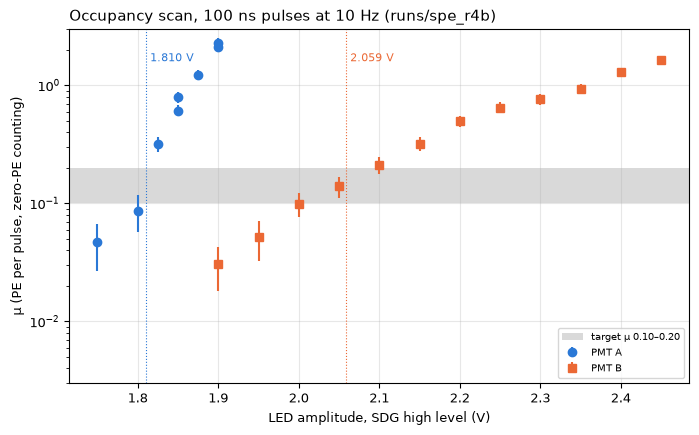

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.axhspan(0.10, 0.20, color="0.85", lw=0, label="target μ 0.10–0.20")
for ch, m in ((A, "o"), (B, "s")):
    for ok in (True, False):
        rr = [r for r in scan if r["ok"] == ok and r[ch]["p0"] > 0.02 and r[ch]["mu"] > 2 * r[ch]["err"]]
        if not rr:
            continue
        ax.errorbar([r["led"] for r in rr], [r[ch]["mu"] for r in rr], [r[ch]["err"] for r in rr], fmt=m, ms=6,
                    color=COL[ch], mfc=COL[ch] if ok else "white", capsize=0,
                    label=NAME[ch] if ok else f"{NAME[ch]}, 50 Ω terminator point (not used)")
    ax.axvline(cal_amp[ch], color=COL[ch], lw=0.8, ls=":")
    ax.text(cal_amp[ch], 1.6, f" {cal_amp[ch]:.3f} V", color=COL[ch], fontsize=8)
ax.set_yscale("log"); ax.set_ylim(3e-3, 3)
ax.set_xlabel("LED amplitude, SDG high level (V)"); ax.set_ylabel("μ (PE per pulse, zero-PE counting)")
ax.set_title("Occupancy scan, 100 ns pulses at 10 Hz (runs/spe_r4b)", loc="left")
ax.legend(loc="lower right")
save(fig, "spe_occupancy_scan"); plt.show()

The chain used **A at 1.81 V and B at 2.055 V**, rounded from this scan.
- **Near 1.8 V the LED is still turning on:** A's μ grows ×2–3 per 25 mV, about as steep as with the AD3.
- **By 2.0–2.1 V the light curve is much gentler:** B's μ, and A's charge in section 2, grow ×2 per ~100 mV.
- The Ch3 drive is ~0.87 × the setting for 100 ns pulses (50 Ω source into the tee and LED).

The scan had to be repeated once: after a power cycle the SDG came up in sine mode and ignored the
first pulse-mode command (`runs/spe_r4b/scan_coarse_failed_sine.log`). `SiglentSDG` now repeats that command until
the read-back confirms pulse mode.

### 1b. SPE fits (`runs/saturation_r4/spe`, 5000 pulses each)

In [5]:
cal = {}
for ch in (A, B):
    q_s, q_c = [], []
    for f in sorted((RUN_DIR / "spe").glob(f"cal_ch{ch}_part*.npz")):
        fs = FrameSet.load(f)
        s, c = spe_charges(fs, ch)
        q_s.append(s); q_c.append(c)
    s, c = np.concatenate(q_s), np.concatenate(q_c)
    o = occupancy(s, c, N_SIGMA)
    cal[ch] = {"led": fs.meta["amplitude_V"], "rate": fs.meta["rate_Hz"], "q_s": s, "q_c": c, "occ": o,
               "fit": fit_spe(s, mu_guess=o.mu)}
Q1 = {ch: cal[ch]["fit"].q1_pC for ch in cal}

print("             LED V  pulses  zero-PE mu   fit mu    Q1 (pC)          sigma1 (pC)  pedestal sigma (pC)  gain")
for ch, c in cal.items():
    f = c["fit"]
    print(f"{NAME[ch]:10s}  {c['led']:.3f}  {len(c['q_s']):6d}   {c['occ'].mu:.4f}     {f.mu:.4f}   "
          f"{f.q1_pC:.4f} ± {f.q1_err_pC:.4f}   {f.sigma1_pC:.3f}        {f.sigma0_pC:.3f}              {f.gain:.3g}")
summary["spe"] = {NAME[ch]: {"led_V": c["led"], "q1_pC": c["fit"].q1_pC, "q1_err_pC": c["fit"].q1_err_pC,
                             "sigma1_pC": c["fit"].sigma1_pC, "gain": c["fit"].gain, "mu_fit": c["fit"].mu,
                             "mu_zero_pe": c["occ"].mu} for ch, c in cal.items()}

             LED V  pulses  zero-PE mu   fit mu    Q1 (pC)          sigma1 (pC)  pedestal sigma (pC)  gain
PMT A       1.810    5000   0.1721     0.1826   0.9036 ± 0.0128   0.250        0.133              5.64e+06
PMT B       2.055    5000   0.1491     0.1336   1.0804 ± 0.0144   0.278        0.114              6.74e+06


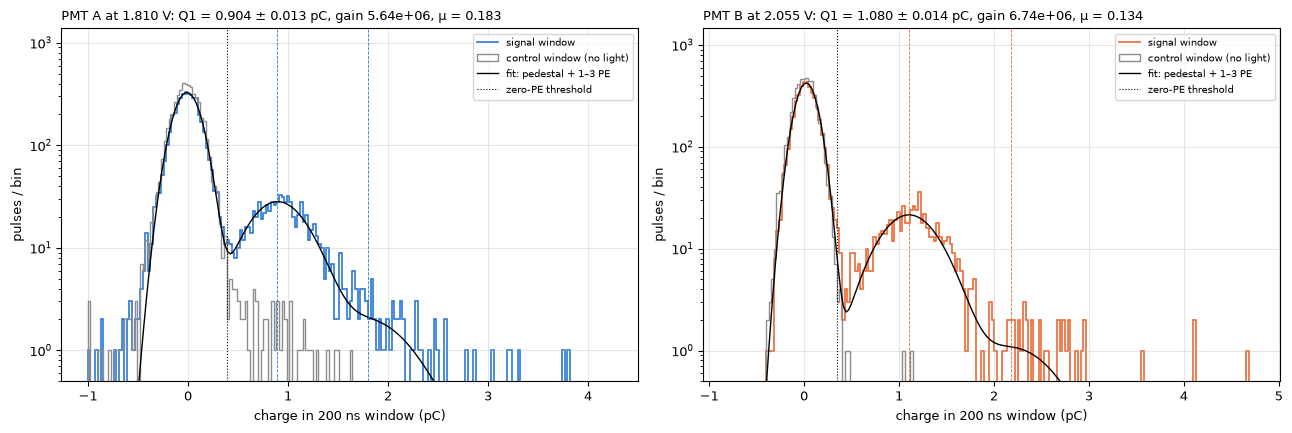

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, (ch, c) in zip(axes, cal.items()):
    f = c["fit"]
    w = f.bin_centers[1] - f.bin_centers[0]
    edges = np.append(f.bin_centers - w / 2, f.bin_centers[-1] + w / 2)
    ax.stairs(f.counts, edges, color=COL[ch], lw=1.2, label="signal window")
    ax.hist(c["q_c"], bins=edges, histtype="step", color="0.55", label="control window (no light)")
    ax.plot(f.bin_centers, f.model, color="k", lw=1, label="fit: pedestal + 1–3 PE")
    ax.axvline(c["occ"].threshold_pC, color="k", ls=":", lw=0.8, label="zero-PE threshold")
    for n in (1, 2):
        ax.axvline(f.q0_pC + n * f.q1_pC, color=COL[ch], ls="--", lw=0.6)
    ax.set_yscale("log"); ax.set_ylim(0.5, None)
    ax.set_xlabel("charge in 200 ns window (pC)"); ax.set_ylabel("pulses / bin")
    ax.set_title(f"{NAME[ch]} at {c['led']:.3f} V: Q1 = {f.q1_pC:.3f} ± {f.q1_err_pC:.3f} pC, "
                 f"gain {f.gain:.3g}, μ = {f.mu:.3f}", loc="left", fontsize=9)
    ax.legend()
fig.tight_layout(); save(fig, "spe_fits"); plt.show()

**Results:**
- **PMT A: Q1 = 0.904 ± 0.013 pC (gain 5.6 × 10⁶).** That is 3.4 % below round 3 (0.935 pC), within ~2σ.
- **PMT B: Q1 = 1.080 ± 0.014 pC (gain 6.7 × 10⁶).** Round 3 gave 1.089 pC.
- Both tubes show a single-PE peak well clear of the pedestal. The control-window spectrum (dark counts) is small.
- The fitted μ is a bit above the zero-PE μ for A (0.183 vs 0.172). This is expected: a few single PEs fall below the
  3σ threshold.

These Q1 values convert every charge below into photoelectrons (PE).

## 2. Light ratio k = A/B

B is the light reference, so we need the ratio k of A's light to B's light, measured where **both tubes are
certainly linear**. At low light:
- **B is photon-counted** (zero-PE μ, as in the SPE scan). This doesn't depend on B's gain calibration, and B gets
  < 1.5 PE per pulse here.
- **A gets ~10–200 PE**, too many for zero-PE counting (P0 ≈ 0), so A is measured by its **mean charge / Q1**. A is
  far below saturation here (it starts to fall behind at ~1500 PE, section 3).

k = (A charge / Q1_A) / μ_B, per LED point, then a weighted mean.

Two measurements:
1. **Light-split run** (`runs/spe_r4b/split`, before the chain). It used B's scan with A's channel set to
   50 mV/div so A doesn't clip: 400 pulses per point, 1.85–2.2 V, B threshold at 3 robust σ.
2. **Ratio scan** (chain, 17:02): 2.0–2.4 V, 1000 pulses per point, auto-ranged channels. B's threshold is fixed
   at 0.25 Q1 above the pedestal (`RATIO_THRESHOLD_Q1`), with a 0.5 % correction for single PEs below it. In
   round 3 a 3σ threshold lost single PEs and biased k high by 6 %.

In [7]:
def clip_fraction(codes):
    # fraction of pulses touching the lowest code of the run (negative pulses clipped at the screen edge)
    lo = codes.min()
    return float(np.mean((codes <= lo).any(axis=1))) if (codes <= lo).sum() > 2 else 0.0


split = []
for f in sorted(SPLIT_DIR.glob("scan_ch2_*V_*.npz")):
    fs = FrameSet.load(f)
    sa, ca = spe_charges(fs, A)
    sb, cb = spe_charges(fs, B)
    ob = occupancy(sb, cb, N_SIGMA)
    a_pe = (sa.mean() - ca.mean()) / Q1[A]
    a_err = np.std(sa, ddof=1) / np.sqrt(len(sa)) / Q1[A]
    split.append({"led": fs.meta["amplitude_V"], "a": a_pe, "a_err": a_err, "mu_b": ob.mu,
                  "mu_b_err": mu_err(ob, len(cb)), "clip": clip_fraction(fs.codes[A]), "n": fs.n_frames})

print("light-split run:  LED V   A (charge/Q1)   B mu             A/B          A clipped")
use = []
for r in split:
    r["k"] = r["a"] / r["mu_b"]
    r["k_err"] = r["k"] * np.hypot(r["a_err"] / r["a"], r["mu_b_err"] / r["mu_b"])
    r["use"] = r["clip"] <= 0.01 and r["mu_b"] > 3 * r["mu_b_err"]
    print(f"                  {r['led']:.3f}   {r['a']:7.2f} ± {r['a_err']:.2f}   {r['mu_b']:.4f} ± {r['mu_b_err']:.4f}"
          f"   {r['k']:6.1f} ± {r['k_err']:4.1f}   {r['clip']:4.0%}" + ("" if r["use"] else "   not used"))
ku = np.array([r["k"] for r in split if r["use"]]); kue = np.array([r["k_err"] for r in split if r["use"]])
w = 1 / kue ** 2
k_split, k_split_err = float(np.sum(w * ku) / np.sum(w)), float(1 / np.sqrt(np.sum(w)))
chi2 = float(np.sum(w * (ku - k_split) ** 2))
print(f"light-split run: k = {k_split:.1f} ± {k_split_err:.1f} (chi2 {chi2:.1f} / {len(ku) - 1}), with Q1_A = {Q1[A]:.4f} pC")

light-split run:  LED V   A (charge/Q1)   B mu             A/B          A clipped
                  1.850      0.79 ± 0.05   0.0050 ± 0.0035    157.5 ± 111.8     0%   not used
                  1.900      2.46 ± 0.08   0.0126 ± 0.0067    195.0 ± 103.2     0%   not used
                  2.000     11.79 ± 0.18   0.0971 ± 0.0160    121.4 ± 20.1     0%
                  2.050     21.40 ± 0.26   0.1512 ± 0.0205    141.5 ± 19.3     0%
                  2.100     33.04 ± 0.30   0.2169 ± 0.0246    152.3 ± 17.3     0%
                  2.150     47.73 ± 0.37   0.3968 ± 0.0349    120.3 ± 10.6     0%
                  2.200     66.40 ± 0.44   0.4877 ± 0.0398    136.1 ± 11.2     0%
light-split run: k = 131.9 ± 6.3 (chi2 3.2 / 4), with Q1_A = 0.9036 pC


In [8]:
ratio_files = sorted(RUN_DIR.glob("ratio_*V_*.npz"))
ratio_rows = sorted((summarize_ratio(FrameSet.load(f), SHORT, Q1, threshold_q1=RATIO_THRESHOLD_Q1) for f in ratio_files),
                    key=lambda r: r["amplitude_V"])
kres = ratio_k(ratio_rows, a_max_pe=RATIO_A_MAX_PE, spe_loss_b=SPE_LOSS_B)
k_ratio, k_ratio_err = kres["k_mean"], kres["k_mean_err"]

print("ratio scan:  LED V   A (charge/Q1)    B mu              B charge/Q1      k")
for r, k, ke in zip(ratio_rows, kres["k"], kres["k_err"]):
    print(f"             {r['amplitude_V']:.3f}  {r[A]['pe']:7.2f} ± {r[A]['pe_err']:.2f}   {r[B]['mu']:.4f} ± {r[B]['mu_err']:.4f}"
          f"   {r[B]['pe']:.4f} ± {r[B]['pe_err']:.4f}   {k:6.1f} ± {ke:4.1f}")
print(f"ratio scan: k = {k_ratio:.1f} ± {k_ratio_err:.1f} from {kres['use'].sum()} points (chi2/dof {kres['chi2_dof']:.2f})")

# The saturation scans measure B by its charge / Q1 (no counting), so the scale for them is k against B's charge:
rows_q = [{**r, B: {**r[B], "mu": r[B]["pe"], "mu_err": r[B]["pe_err"]}} for r in ratio_rows]
kres_q = ratio_k(rows_q, a_max_pe=RATIO_A_MAX_PE, spe_loss_b=0.0)
k_ratio_q, k_ratio_q_err = kres_q["k_mean"], kres_q["k_mean_err"]
print(f"ratio scan, B by charge/Q1: k_q = {k_ratio_q:.1f} ± {k_ratio_q_err:.1f} (chi2/dof {kres_q['chi2_dof']:.2f})")
summary["k"] = {"ratio_scan": k_ratio, "ratio_scan_err": k_ratio_err, "ratio_scan_chi2_dof": kres["chi2_dof"],
                "ratio_scan_B_charge": k_ratio_q, "ratio_scan_B_charge_err": k_ratio_q_err,
                "split_run": k_split, "split_run_err": k_split_err}

ratio scan:  LED V   A (charge/Q1)    B mu              B charge/Q1      k
             2.000    12.19 ± 0.12   0.0838 ± 0.0099   0.0779 ± 0.0099    144.7 ± 17.1
             2.050    21.07 ± 0.15   0.1498 ± 0.0128   0.1523 ± 0.0133    140.0 ± 12.0
             2.100    33.15 ± 0.19   0.2626 ± 0.0176   0.2488 ± 0.0163    125.6 ±  8.4
             2.150    47.52 ± 0.23   0.3591 ± 0.0213   0.3565 ± 0.0193    131.6 ±  7.8
             2.200    65.56 ± 0.27   0.4969 ± 0.0256   0.4950 ± 0.0230    131.3 ±  6.8
             2.250    87.88 ± 0.31   0.6480 ± 0.0304   0.6258 ± 0.0254    134.9 ±  6.3
             2.300   112.87 ± 0.36   0.7663 ± 0.0343   0.7736 ± 0.0283    146.5 ±  6.6
             2.350   141.10 ± 0.40   1.0040 ± 0.0426   0.9924 ± 0.0333    139.8 ±  6.0
             2.400   175.07 ± 0.44   1.2228 ± 0.0496   1.2222 ± 0.0370    142.5 ±  5.8
ratio scan: k = 137.5 ± 2.4 from 9 points (chi2/dof 0.82)
ratio scan, B by charge/Q1: k_q = 140.4 ± 2.1 (chi2/dof 0.70)


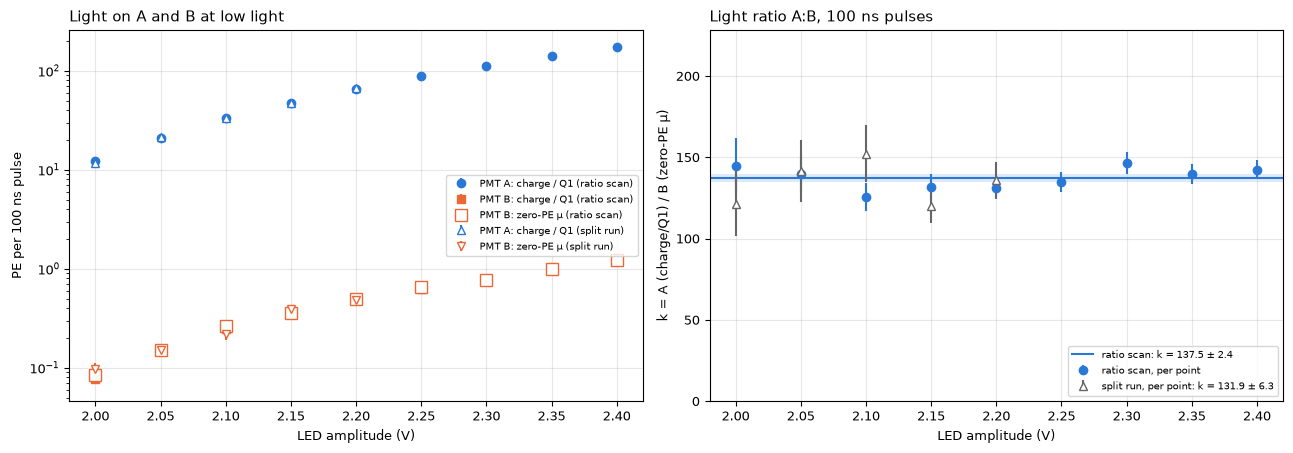

B charge/Q1 over B zero-PE mu, per ratio-scan point: 0.929 1.017 0.948 0.993 0.996 0.966 1.010 0.989 1.000
weighted mean 0.989


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
amp_r = np.array([r["amplitude_V"] for r in ratio_rows])
for ch, m in ((A, "o"), (B, "s")):
    pe = np.array([r[ch]["pe"] for r in ratio_rows]); pee = np.array([r[ch]["pe_err"] for r in ratio_rows])
    ax.errorbar(amp_r, pe, pee, fmt=m, color=COL[ch], ms=6, label=f"{NAME[ch]}: charge / Q1 (ratio scan)")
mu = np.array([r[B]["mu"] for r in ratio_rows]); mue = np.array([r[B]["mu_err"] for r in ratio_rows])
ax.errorbar(amp_r, mu, mue, fmt="s", color=COL[B], mfc="white", ms=8, label="PMT B: zero-PE μ (ratio scan)")
sp = [r for r in split if r["use"]]
ax.errorbar([r["led"] for r in sp], [r["a"] for r in sp], [r["a_err"] for r in sp], fmt="^", color=COL[A], mfc="white",
            ms=6, label="PMT A: charge / Q1 (split run)")
ax.errorbar([r["led"] for r in sp], [r["mu_b"] for r in sp], [r["mu_b_err"] for r in sp], fmt="v", color=COL[B],
            mfc="white", ms=6, label="PMT B: zero-PE μ (split run)")
ax.set_yscale("log"); ax.set_xlabel("LED amplitude (V)"); ax.set_ylabel("PE per 100 ns pulse")
ax.set_title("Light on A and B at low light", loc="left"); ax.legend(loc="center right")

ax = axes[1]
ax.axhspan(k_ratio - k_ratio_err, k_ratio + k_ratio_err, color=COL[A], alpha=0.15, lw=0)
ax.axhline(k_ratio, color=COL[A], lw=1.5, label=f"ratio scan: k = {k_ratio:.1f} ± {k_ratio_err:.1f}")
ax.errorbar(amp_r, kres["k"], kres["k_err"], fmt="o", color=COL[A], ms=6, label="ratio scan, per point")
ax.errorbar([r["led"] for r in sp], [r["k"] for r in sp], [r["k_err"] for r in sp], fmt="^", color="0.4",
            mfc="white", ms=6, label=f"split run, per point: k = {k_split:.1f} ± {k_split_err:.1f}")
ax.set_ylim(0, 1.5 * max(kres["k"].max(), max(r["k"] for r in sp)))
ax.set_xlabel("LED amplitude (V)"); ax.set_ylabel("k = A (charge/Q1) / B (zero-PE μ)")
ax.set_title("Light ratio A:B, 100 ns pulses", loc="left"); ax.legend(loc="lower right")
fig.tight_layout(); save(fig, "light_ratio"); plt.show()

# B's charge/Q1 against its counted mu: B's SPE calibration holds at these levels
bq = np.array([r[B]["pe"] for r in ratio_rows])
print("B charge/Q1 over B zero-PE mu, per ratio-scan point:", " ".join(f"{x:.3f}" for x in bq / mu))
print(f"weighted mean {np.average(bq / mu, weights=(mu / mue) ** 2):.3f}")

**Results:**
- **k = 137.5 ± 2.4** from the ratio scan (9 points, χ²/dof 0.8), flat across 2.0–2.4 V. It is about 5× round 3's
  ≈ 28: the user dimmed B for this round.
- The light-split run agrees: **≈ 132 ± 6** with this round's Q1_A. With round 3's Q1_A (0.935 pC) it gave 127 ± 6,
  the number quoted before the chain.
- **B's charge/Q1 matches its photon count to ~1 %** (ratio 0.989). So B's SPE calibration holds, and B's
  *charge* can be used as its light measure at higher light, where counting fails. The saturation scans use B's
  charge, so their direct light scale uses the same ratio scan with B by charge: **k_q = 140.4 ± 2.1**.
- The light split is stable over the ~2 h between the two measurements. The tubes didn't move with the new mounting.

## 3. Saturation scans: data selection and the A/B ratio against drive

Each saturation point records 150–200 pulses at 4 Hz, with Ch1 and Ch2 auto-ranged so the pulses fill the screen
without clipping. Per point and tube, from the raw files:
- **charge** in the signal window (100 ns: 40–440 ns; 10 µs: 0–12 µs) minus the light-free control-window charge,
  scaled to the same width. Converted to PE with Q1;
- **peak current**: the maximum of the 5-sample-smoothed current into 50 Ω;
- **pulse shape**: FWHM of the mean pulse (100 ns), and late/early charge (10 µs: charge in 7–9 µs over 1–3 µs);
- a check for **pickup bursts**: pulses with a large swing before the light, or an off LED drive on Ch3, are dropped.
  That is 0–4 of 200 pulses per point.

**Excluded: the first up-sweep point of each scan** (100 ns at 2.000 V, 10 µs at 1.700 V). On both, Ch3 shows the
LED at ~0.4–0.5 V instead of the setting, so the LED was barely on. **Cause, found while writing this up:**
1. The timing check before each scan runs at 2.0 V (100 ns) or 1.7 V (10 µs), the same value as the first scan point.
2. The scan then restarts the pulse train at a safe 0.5 V.
3. `ScopeSession.set_amplitude()` skipped the "unchanged" first amplitude, so the first point was recorded at
   0.5 V.

It is fixed now (`ad3pulse/acquire.py`: the amplitude is always sent; test
`test_set_amplitude_is_resent_after_the_pulser_was_restarted`). No other point is affected: every other point has a
new amplitude.

In [10]:
EXCLUDE = {("short", "up", 2.000), ("long", "up", 1.700)}   # recorded at the 0.5 V start level (see above)
scans = {}
for regime, cfg in CFG.items():
    pts, stamp = load_scan(RUN_DIR, regime, cfg, Q1)
    keep = []
    for p in pts:
        if (regime, p.sweep, round(p.amp, 3)) in EXCLUDE:
            print(f"{regime} {p.sweep} {p.amp:.3f} V excluded: Ch3 {p.r50['pulser_height_V']:.2f} V, "
                  f"A {p.r50['ch'][A]['pe']:.1f} PE, {p.r50['n_rejected']}/{p.r50['n_frames']} pulses flagged")
        else:
            keep.append(p)
    scans[regime] = keep
    n_up = sum(p.sweep == "up" for p in keep)
    print(f"{regime}: run {stamp}, {n_up} up + {len(keep) - n_up} down points, "
          f"{sum(p.r50['n_rejected'] for p in keep)} pulses dropped as bursts in total")


def arrays(pts, ch, key):
    return (np.array([p.r50["ch"][ch][key] for p in pts], float),
            np.array([p.r50["ch"][ch].get(key + "_err", np.nan) for p in pts], float))


def sweeps(pts):
    return np.array([p.sweep for p in pts])

short up 2.000 V excluded: Ch3 0.37 V, A 0.0 PE, 59/200 pulses flagged
short: run 20261114_175157, 45 up + 15 down points, 4 pulses dropped as bursts in total


long up 1.700 V excluded: Ch3 0.50 V, A -0.2 PE, 0/150 pulses flagged
long: run 20261114_195224, 43 up + 15 down points, 18 pulses dropped as bursts in total


### A/B against LED drive
If both tubes were linear and the light split fixed, A/B would be one flat line. The filled points have B
significant and A below the top of its linear window (100 ns: 1000 PE; 10 µs: 11 000 PE) and before A's maximum.
Open points are past that. The ratio-scan k (100 ns, low light) is the dashed black line.

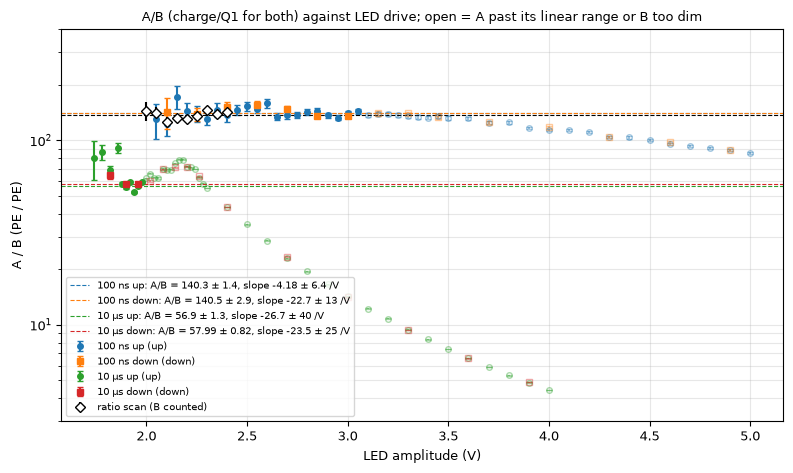

100 ns up   : A/B = 140.3 ± 1.4 from 21 points (chi2/dof 1.0), slope -4 ± 6 per V
100 ns down : A/B = 140.5 ± 2.9 from 7 points (chi2/dof 1.5), slope -23 ± 13 per V
10 µs up    : A/B = 56.9 ± 1.3 from 10 points (chi2/dof 12.3), slope -27 ± 40 per V
10 µs down  : A/B = 58.0 ± 0.8 from 3 points (chi2/dof 2.0), slope -23 ± 25 per V


In [11]:
ab = {}
for regime, a_max in (("short", 1000.0), ("long", 11000.0)):
    for sw in ("up", "down"):
        pts = [p for p in scans[regime] if p.sweep == sw]
        b, be, _ = b_measure(pts)
        ab[f"{'100 ns' if regime == 'short' else '10 µs'} {sw}"] = ab_ratio(pts, a_max, b, be)
fig = sat_plots.plot_ab_ratio(ab, "A/B (charge/Q1 for both) against LED drive; open = A past its linear range or B too dim")
ax = fig.axes[0]
ax.errorbar(amp_r, kres["k"], kres["k_err"], fmt="D", ms=5, color="k", mfc="white", label="ratio scan (B counted)")
ax.axhline(k_ratio, color="k", ls="--", lw=0.8)
ax.set_ylim(3, 400); ax.legend(fontsize=7, loc="lower left")
save(fig, "ab_ratio_vs_led"); plt.show()
for name, r in ab.items():
    print(f"{name:12s}: A/B = {r['mean']:.1f} ± {r['mean_err']:.1f} from {r['use'].sum()} points "
          f"(chi2/dof {r['chi2_dof']:.1f}), slope {r['slope_per_V']:.0f} ± {r['slope_err']:.0f} per V")

- **100 ns:** A/B sits at ~137–145 from 2.05 to ~3.3 V (A up to ~1400 PE) in both sweeps, then falls as A saturates.
  Up and down sweeps agree point by point, so nothing moved during the 2 h scan.
- **10 µs:** A/B ≈ 52–60 for 1.88–1.98 V, then rises to ~78 at 2.16 V before A collapses. The long/short ratio
  (~56/137 ≈ 0.41) is the LED-regime dependence seen before (round 2: 0.46, round 3: 0.49). For 10 µs pulses B
  gets relatively more light; the calibration of each regime must use its own k (section 5).
- Below ~1.86 V for 10 µs, B gets only 2–20 PE spread over 10 µs, so its charge is noisy (±0.5–1.4 PE), and so is A/B.

## 4. 100 ns pulses: space-charge saturation

### True light from B
B gets 0.2–43 PE per pulse over the whole scan, with peak currents ≤ 1 mA, so it stays linear: compare its ~34 mA
saturation in A's case. Two equivalent ways turn B into the true light seen by A:
1. **Direct:** true light = k_q × B per point, with the independent low-light ratio scan's k_q (k against B's
   charge, section 2).
2. **Matched (the default since round 2):** B is smoothed against LED drive with a weighted spline, and its scale
   k_match is fitted to A on the points where A is still clearly linear (A = 400–1000 PE). Below that window's top,
   A's own PE are the light; above it, k_match × B_smooth. This uses many points of B, and it ties the scale to
   A's own linear range rather than to a separate low-light run.

The two scales differ only by k_match / k (below). The deviation is **measured / true − 1**.

In [12]:
def light_scales(pts, window, k_direct, k_direct_err):
    b, be, _ = b_measure(pts)                  # B charge / Q1 (no photon counting in these scans)
    ls = light_scale_matched(pts, b, be, window, b_min=REF_MIN_NPE, k_ref=k_direct)
    direct = k_direct * b
    direct_err = np.hypot(k_direct * be, b * k_direct_err)
    return ls, direct, direct_err


def deviations(pts, ls, direct, direct_err, b_rel_max=0.05):
    a, ae = arrays(pts, A, "pe")
    lin = metric_linearity(a, ae, ls["light"], ls["light_err"], ls["window"])
    good = (ls["b"] > 0) & (ls["b_err"] < b_rel_max * ls["b"])   # direct scale: B known to 5 %
    dev_d = a / direct - 1
    dev_d_err = (a / direct) * np.hypot(ae / a, direct_err / direct)
    cross_d = {lv: crossing(direct[good], dev_d[good], lv) for lv in (0.05, 0.10)}
    return {"a": a, "ae": ae, "lin": lin, "good": good, "dev_d": dev_d, "dev_d_err": dev_d_err, "cross_d": cross_d}


pts_s = scans["short"]
ls_s, direct_s, direct_s_err = light_scales(pts_s, (400.0, 1000.0), k_ratio_q, k_ratio_q_err)
dv_s = deviations(pts_s, ls_s, direct_s, direct_s_err)
print(f"matched: k_match = {ls_s['k']:.1f} ± {ls_s['k_err']:.1f} from {ls_s['window'].sum()} points "
      f"(A in 400-1000 PE); ratio scan k_q = {k_ratio_q:.1f} ± {k_ratio_q_err:.1f}; "
      f"k_match / k_q = {ls_s['k'] / k_ratio_q:.3f} ({(ls_s['k'] - k_ratio_q) / np.hypot(ls_s['k_err'], k_ratio_q_err):.1f} sigma)")
for lv in (0.05, 0.10):
    print(f"A charge {lv:.0%} low at true light: matched {dv_s['lin']['cross'][lv]:.0f} PE, "
          f"direct (k_q = {k_ratio_q:.1f}) {dv_s['cross_d'][lv]:.0f} PE")
top = int(np.argmax(ls_s["light"]))
print(f"top of the scan ({pts_s[top].amp:.1f} V): true light {ls_s['light'][top]:,.0f} PE, A {dv_s['a'][top]:,.0f} PE "
      f"({100 * dv_s['lin']['dev'][top]:+.0f} %)")

matched: k_match = 142.5 ± 0.8 from 12 points (A in 400-1000 PE); ratio scan k_q = 140.4 ± 2.1; k_match / k_q = 1.014 (0.9 sigma)
A charge 5% low at true light: matched 1512 PE, direct (k_q = 140.4) 1728 PE
A charge 10% low at true light: matched 2087 PE, direct (k_q = 140.4) 2253 PE
top of the scan (5.0 V): true light 6,174 PE, A 3,664 PE (-41 %)


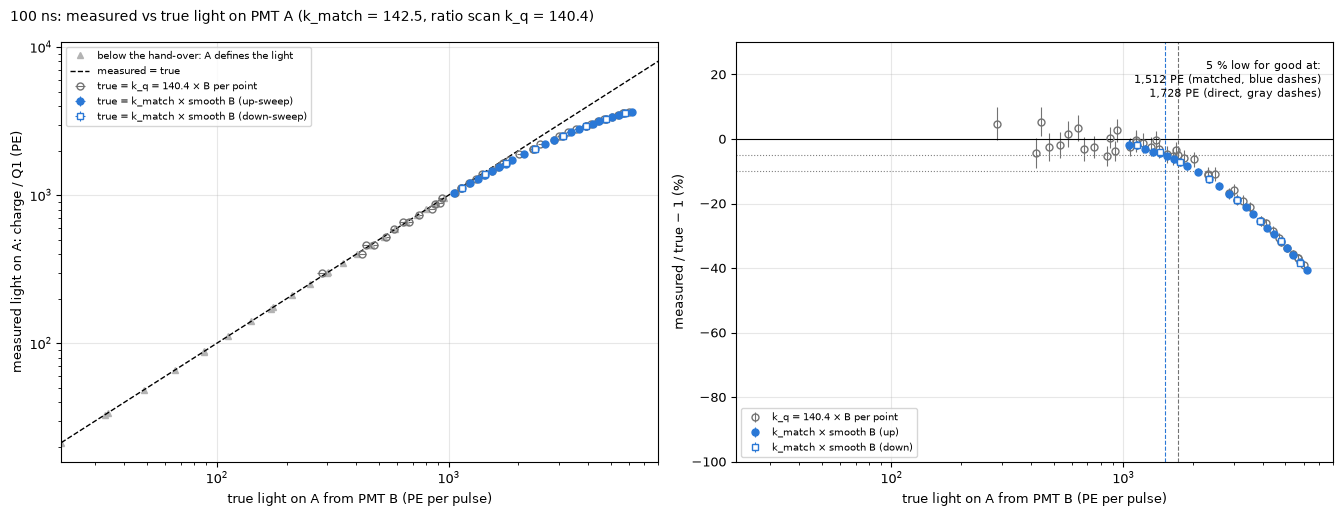

In [13]:
def plot_measured_vs_true(pts, ls, direct, direct_err, dv, k_label, title, b_caution=None, top_dev=30):
    a, ae, sw = dv["a"], dv["ae"], sweeps(pts)
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))
    g = dv["good"]
    linA = ~ls["use_b"]
    for ax, ylog in zip(axes, (True, False)):
        if ylog:
            ax.errorbar(direct[g], a[g], xerr=direct_err[g], fmt="o", ms=5, color="0.45", mfc="none", lw=0.8,
                        label=f"true = {k_label} × B per point")
            for s, m in (("up", "o"), ("down", "s")):
                sel = (sw == s) & ls["use_b"]
                ax.errorbar(ls["light"][sel], a[sel], xerr=ls["light_err"][sel], yerr=ae[sel], fmt=m, ms=5,
                            color=COL[A], mfc=COL[A] if s == "up" else "white", lw=0.8,
                            label=f"true = k_match × smooth B ({s}-sweep)")
            ax.plot(ls["light"][linA], a[linA], "^", ms=4, color="0.7", label="below the hand-over: A defines the light")
            lo = max(np.nanmin(a[a > 0]), 1.0); hi = np.nanmax(np.r_[ls["light"], direct[g]]) * 1.3
            xx = np.geomspace(lo, hi, 50)
            ax.plot(xx, xx, "k--", lw=1, label="measured = true")
            ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lo, hi)
            ax.set_ylabel("measured light on A: charge / Q1 (PE)")
        else:
            ax.errorbar(direct[g], 100 * dv["dev_d"][g], 100 * dv["dev_d_err"][g], fmt="o", ms=5, color="0.45",
                        mfc="none", lw=0.8, label=f"{k_label} × B per point")
            lin = dv["lin"]
            for s, m in (("up", "o"), ("down", "s")):
                sel = (sw == s) & ls["use_b"]
                ax.errorbar(ls["light"][sel], 100 * lin["dev"][sel], 100 * lin["dev_err"][sel], fmt=m, ms=5,
                            color=COL[A], mfc=COL[A] if s == "up" else "white", lw=0.8, label=f"k_match × smooth B ({s})")
            for lv in (-5, -10):
                ax.axhline(lv, color="0.5", ls=":", lw=0.8)
            ax.axhline(0, color="k", lw=0.8)
            c5, c5d = lin["cross"][0.05], dv["cross_d"][0.05]
            for c, col in ((c5, COL[A]), (c5d, "0.45")):
                if c:
                    ax.axvline(c, color=col, lw=0.8, ls="--")
            ax.set_xscale("log"); ax.set_ylim(-100, top_dev)
            ax.set_ylabel("measured / true − 1 (%)")
            ax.text(0.98, 0.96, "5 % low for good at:\n" + (f"{c5:,.0f} PE (matched, blue dashes)" if c5 else "–")
                    + (f"\n{c5d:,.0f} PE (direct, gray dashes)" if c5d else ""), transform=ax.transAxes,
                    fontsize=8, ha="right", va="top")
        if b_caution is not None:
            ax.axvspan(b_caution, ax.get_xlim()[1] if ylog else 1e9, color="#eb6834", alpha=0.08, lw=0,
                       label="B itself less reliable here" if ylog else None)
        ax.set_xlabel("true light on A from PMT B (PE per pulse)")
        ax.legend(loc="upper left" if ylog else "lower left", fontsize=7)
    if not ylog:
        axes[1].set_xlim(axes[0].get_xlim())
    fig.suptitle(title, x=0.01, ha="left", fontsize=10)
    fig.tight_layout()
    return fig


fig = plot_measured_vs_true(pts_s, ls_s, direct_s, direct_s_err, dv_s, f"k_q = {k_ratio_q:.1f}",
                            f"100 ns: measured vs true light on PMT A (k_match = {ls_s['k']:.1f}, ratio scan k_q = {k_ratio_q:.1f})")
save(fig, "short_measured_vs_true"); plt.show()

**Results:**
- **A's charge is 5 % low at ≈ 1500 PE and 10 % low at ≈ 2100 PE** (matched scale). The top of the scan (5 V) has
  ≈ 6200 PE of true light, and A delivers only 3660 PE: 41 % low.
- **The two light scales agree:** k_match = 142.5 ± 0.8 is 1.4 % (0.9σ) above the independent low-light k_q = 140.4
  ± 2.1. A is linear to ~1 % from ~10 PE to ~1000 PE.
- With the direct scale the knee moves up a little: **5 % low at ≈ 1730 PE, 10 % at ≈ 2250 PE**. The 1.4 % offset
  between the scales shifts the light where A falls 5 % behind. The difference, ~1500–1700 PE for 5 %, is the
  systematic uncertainty of the knee.
- The up- and down-sweeps lie on top of each other: no hysteresis or drift.
- Round 2 (AD3, 100 ns, other geometry) gave 1330 / 1590 PE for 5 % / 10 %; round 3 (250 ns) gave 2960 / 4480 PE.

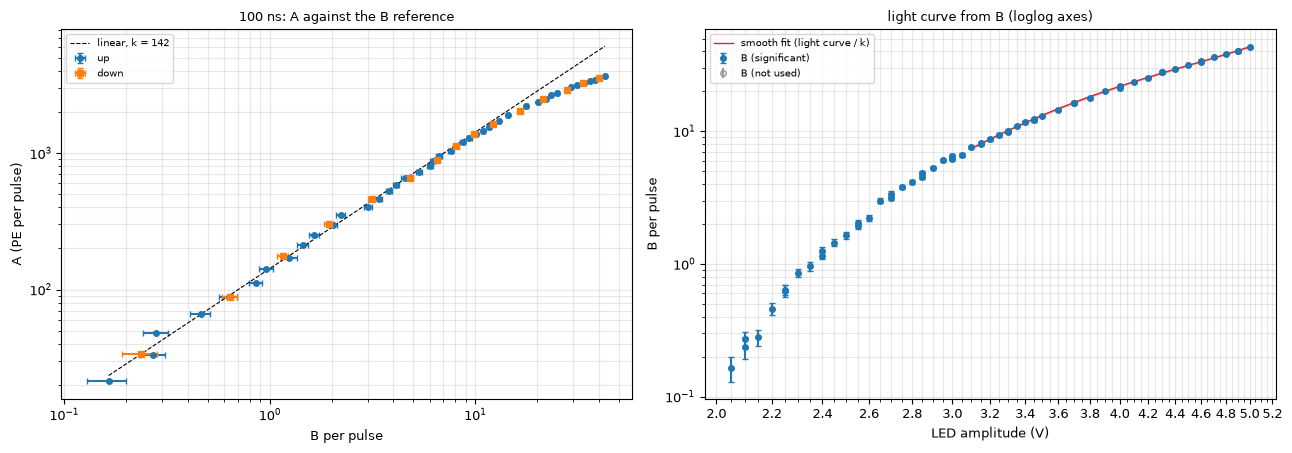

In [14]:
fig = sat_plots.plot_a_vs_b(pts_s, ls_s, ls_s["k"], "100 ns", light_axes="loglog")
save(fig, "short_a_vs_b"); plt.show()

### Raw waveforms of PMT A as it saturates
Single pulses (thin) and the mean of all pulses (thick) at a few LED settings, as anode current into 50 Ω. The dashed
black line is **what A would give if it were linear**: B's mean current × k_match × Q1_A/Q1_B, shifted in time by the
two tubes' transit-time difference (fitted on a linear point). At low light the two agree. As the light rises, A's
current flattens at ~30–34 mA while the expected current keeps growing, and A's pulse broadens.

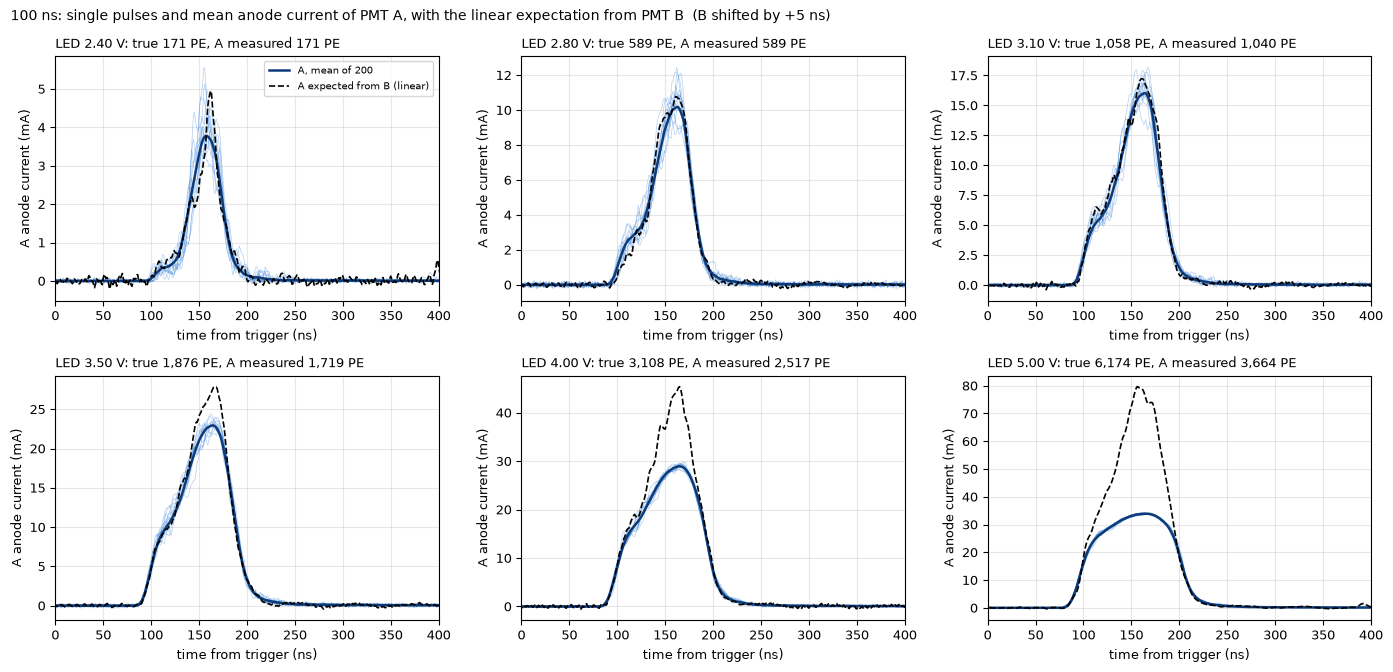

In [15]:
def load_raw(regime, sweep, led):
    f = next(RUN_DIR.glob(f"{regime}_{sweep}_{led:.3f}V_*.npz"))
    fs = FrameSet.load(f)
    cfg = CFG[regime]
    cur = {ch: -baseline_subtract(fs.volts(ch), fs.time_s, cfg["baseline"], False) / R_OHM * 1e3 for ch in (A, B)}
    ctl = window_mask(fs.time_s, cfg["control"])
    for ch in cur:                             # remove the small median-vs-mean baseline offset (dark pulses)
        cur[ch] = cur[ch] - cur[ch][:, ctl].mean()
    return fs.time_s, cur, fs


def boxcar(x, n):
    return np.convolve(x, np.ones(n) / n, mode="same") if n > 1 else x


def expected_from_b(t, cur, k, shift, smooth):
    # A's current if linear: B mean current x k x Q1_A / Q1_B, moved by the transit-time difference
    bm = boxcar(cur[B].mean(axis=0), smooth) * k * Q1[A] / Q1[B]
    return np.roll(bm, int(round(shift / (t[1] - t[0]))))


def point_light(pts, ls, sweep, led):
    i = next(i for i, p in enumerate(pts) if p.sweep == sweep and abs(p.amp - led) < 1e-6)
    return ls["light"][i], pts[i].r50["ch"][A]["pe"]


def plot_raw(regime, pts, ls, leds, k, align_led, smooth, xlim, unit_s, n_single, title):
    t, cur, _ = load_raw(regime, "up", align_led)
    sig = window_mask(t, CFG[regime]["signal"])
    shift = align_shift(t[sig], cur[A].mean(axis=0)[sig], boxcar(cur[B].mean(axis=0), smooth)[sig],
                        max_shift_s=60e-9 if regime == "short" else 0.5e-6)
    ncol = 3
    fig, axes = plt.subplots(int(np.ceil(len(leds) / ncol)), ncol, figsize=(14, 3.4 * np.ceil(len(leds) / ncol)),
                             squeeze=False)
    for ax, led in zip(axes.flat, leds):
        t, cur, fs = load_raw(regime, "up", led)
        ts = t / unit_s
        for i in range(min(n_single, fs.n_frames)):
            ax.plot(ts, cur[A][i], color=COL[A], lw=0.5, alpha=0.35)
        ax.plot(ts, cur[A].mean(axis=0), color="#0d3b7a", lw=1.8, label=f"A, mean of {fs.n_frames}")
        ax.plot(ts, expected_from_b(t, cur, k, shift, smooth), "k--", lw=1.2, label="A expected from B (linear)")
        light, meas = point_light(pts, ls, "up", led)
        ax.set_title(f"LED {led:.2f} V: true {light:,.0f} PE, A measured {meas:,.0f} PE", fontsize=9, loc="left")
        ax.set_xlim(*xlim); ax.set_xlabel(f"time from trigger ({'ns' if unit_s == 1e-9 else 'µs'})")
        ax.set_ylabel("A anode current (mA)")
    axes.flat[0].legend(loc="upper right")
    for ax in list(axes.flat)[len(leds):]:
        ax.set_visible(False)
    fig.suptitle(title + f"  (B shifted by {shift / unit_s:+.0f} {'ns' if unit_s == 1e-9 else 'µs'})",
                 x=0.01, ha="left", fontsize=10)
    fig.tight_layout()
    return fig


fig = plot_raw("short", pts_s, ls_s, [2.40, 2.80, 3.10, 3.50, 4.00, 5.00], ls_s["k"], 2.80, 5, (0, 400), 1e-9, 12,
               "100 ns: single pulses and mean anode current of PMT A, with the linear expectation from PMT B")
save(fig, "short_raw_waveforms"); plt.show()

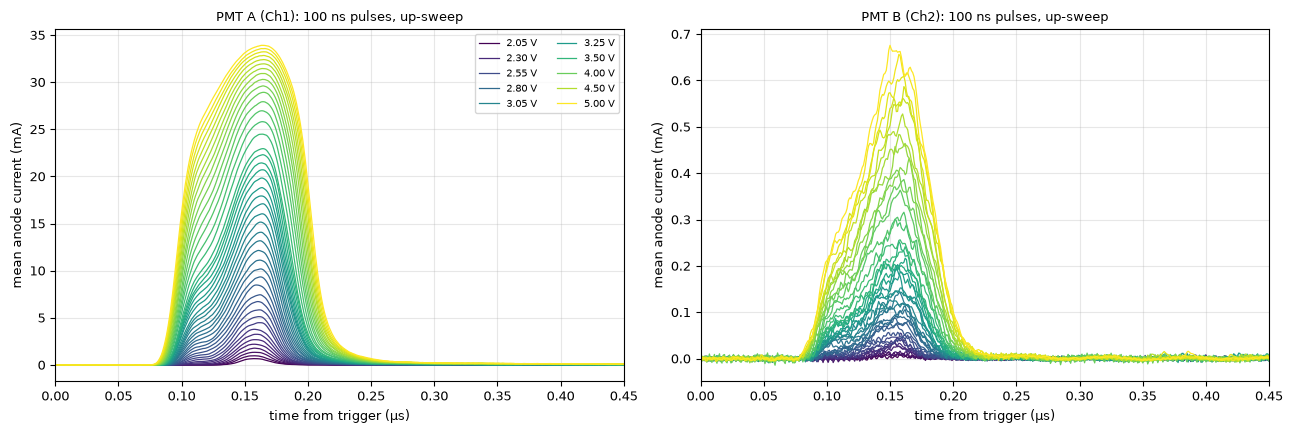

In [16]:
fig = sat_plots.plot_waveforms(pts_s, "100 ns", xlim_us=(0.0, 0.45))
save(fig, "short_mean_waveforms"); plt.show()

Mean anode current of A and B at every up-sweep LED setting (viridis: dim → bright). A's peak stops growing at ~30–34 mA
and its pulse widens to the full ~100 ns of the light pulse. B keeps its shape. Normalising A's current to the true light
shows the same thing as a "response per photoelectron". As A saturates (yellow), the peak per PE drops several-fold
and the pulse flattens over the whole light pulse. The early shoulder at 100–130 ns already grows between 21 and 300 PE,
where A is still linear. That is the LED: its light pulse gets more of its light early as the drive rises, which is why
the pulse shape changes with drive even in B, and why peak current is not a clean linearity measure.

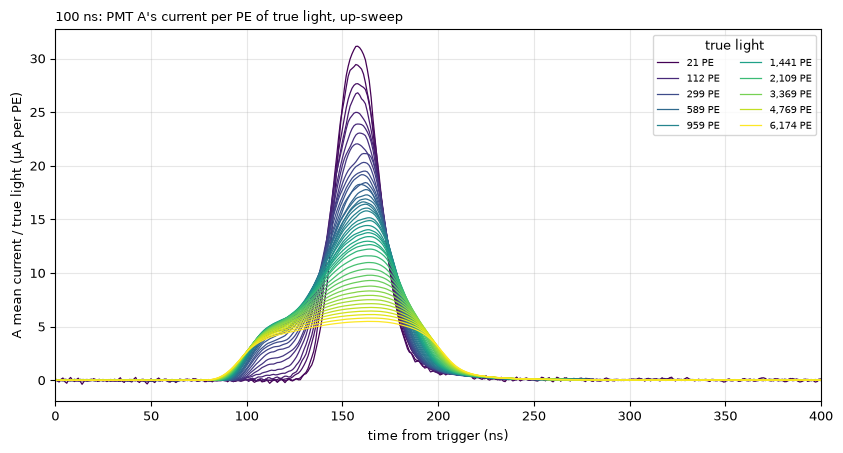

In [17]:
def plot_response_per_pe(regime, pts, ls, xlim, unit_s, title):
    up = sorted((i for i, p in enumerate(pts) if p.sweep == "up"), key=lambda i: pts[i].amp)
    cmap = plt.get_cmap("viridis")
    fig, ax = plt.subplots(figsize=(8.5, 4.6))
    for j, i in enumerate(up):
        p = pts[i]
        cur = -p.r50["ch"][A]["mean_v"] / R_OHM * 1e6        # µA
        ax.plot(p.r50["t"] / unit_s, cur / ls["light"][i], color=cmap(j / max(len(up) - 1, 1)), lw=0.9,
                label=f"{ls['light'][i]:,.0f} PE" if j % max(len(up) // 8, 1) == 0 or j == len(up) - 1 else None)
    ax.set_xlim(*xlim); ax.set_xlabel(f"time from trigger ({'ns' if unit_s == 1e-9 else 'µs'})")
    ax.set_ylabel("A mean current / true light (µA per PE)")
    ax.set_title(title, loc="left", fontsize=9); ax.legend(title="true light", ncol=2)
    fig.tight_layout()
    return fig


fig = plot_response_per_pe("short", pts_s, ls_s, (0, 400), 1e-9, "100 ns: PMT A's current per PE of true light, up-sweep")
save(fig, "short_response_per_pe"); plt.show()

### Peak current and pulse width

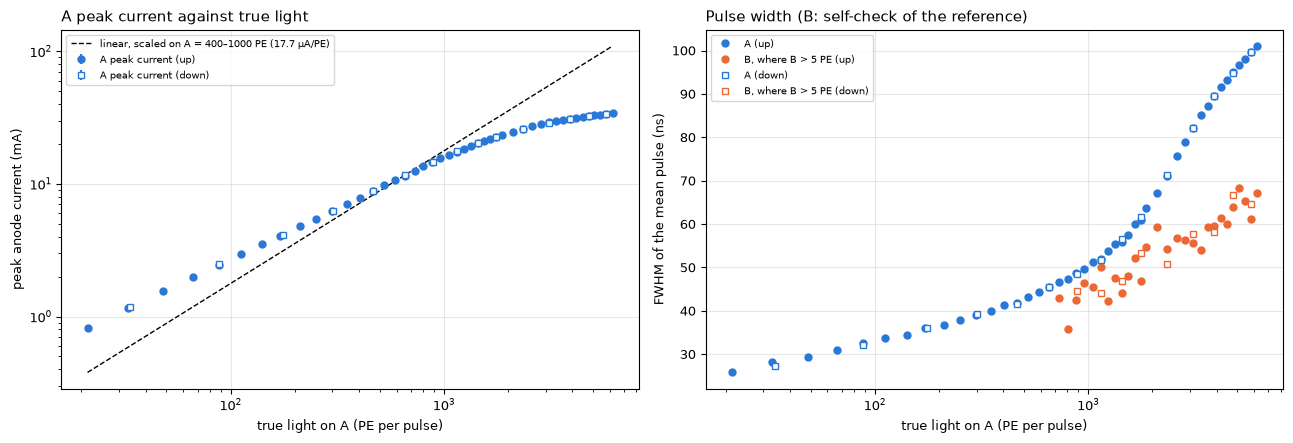

A peak current at the top (5.0 V, 6,174 PE true): 34.0 mA; linear would be 110 mA


In [18]:
pk, pke = arrays(pts_s, A, "peak_mA")
fw = np.array([p.r50["ch"][A]["fwhm_s"] for p in pts_s]) * 1e9
fwb = np.array([p.r50["ch"][B]["fwhm_s"] for p in pts_s]) * 1e9
bpe = ls_s["b"]
sw = sweeps(pts_s)
light = ls_s["light"]
scale_pk = np.average(pk[ls_s["window"]] / light[ls_s["window"]])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
for s, m in (("up", "o"), ("down", "s")):
    sel = sw == s
    ax.errorbar(light[sel], pk[sel], pke[sel], fmt=m, ms=5, color=COL[A], mfc=COL[A] if s == "up" else "white",
                label=f"A peak current ({s})")
xx = np.geomspace(light.min(), light.max(), 50)
ax.plot(xx, scale_pk * xx, "k--", lw=1, label=f"linear, scaled on A = 400–1000 PE ({scale_pk * 1e3:.1f} µA/PE)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("true light on A (PE per pulse)"); ax.set_ylabel("peak anode current (mA)")
ax.set_title("A peak current against true light", loc="left"); ax.legend()
ax = axes[1]
ok = bpe > 5                                   # B's mean-pulse width is noise below ~5 PE
for s, m in (("up", "o"), ("down", "s")):
    sel = sw == s
    ax.plot(light[sel], fw[sel], m, ms=5, color=COL[A], mfc=COL[A] if s == "up" else "white", label=f"A ({s})")
    ax.plot(light[sel & ok], fwb[sel & ok], m, ms=5, color=COL[B], mfc=COL[B] if s == "up" else "white",
            label=f"B, where B > 5 PE ({s})")
ax.set_xscale("log"); ax.set_xlabel("true light on A (PE per pulse)"); ax.set_ylabel("FWHM of the mean pulse (ns)")
ax.set_title("Pulse width (B: self-check of the reference)", loc="left"); ax.legend()
fig.tight_layout(); save(fig, "short_peak_and_width"); plt.show()
top = int(np.argmax(light))
print(f"A peak current at the top ({pts_s[top].amp:.1f} V, {light[top]:,.0f} PE true): {pk[top]:.1f} mA; "
      f"linear would be {scale_pk * light[top]:.0f} mA")

- **The peak current flattens at ~34 mA:** 34.0 mA at the top, against ~110 mA if linear. Round 2 gave ~39 mA, round
  3 ~38 mA. The peak per PE starts to fall well before the charge does. The anode charge keeps rising because the pulse
  widens: at saturation A's FWHM grows from ~45 ns to ~100 ns, the full light pulse. So the peak current, not the charge,
  is the quantity that saturates first for short pulses.
- The automatic "5 % crossing" of the peak current (~900 PE in `short_summary_*.json`) is not a clean number. The
  peak per PE is not constant even at low light: the mean pulse also widens slowly with drive (A's FWHM goes from 26 to
  45 ns between 2.05 and 2.85 V), because the LED's light pulse changes shape with drive.
- **B self-check:** B's FWHM rises from ~45 to ~65 ns over the same range, which follows the LED. Its peak is < 1 mA,
  so B isn't near space charge. Its pulse doesn't flatten.

## 5. 10 µs pulses: base depletion

The 10 µs record is read back at 20 ns spacing. B's single-PE pulses (a few ns) are then undersampled, so B can't be
photon-counted. Its charge/Q1 is used instead: it averages correctly over many pulses, and section 2 shows it matches the
photon count. B gets up to ~6600 PE (7 nC) per 10 µs pulse at 4 V.

### Choosing the light scale: A(t)/B(t) through the pulse
The default matched window for 10 µs (A = 5000–30 000 PE) gave k_match = 63.1 in the chain, and an A/B that drifts with
drive (section 3). To tell a light-split change from a gain change in A, split each pulse into 1 µs bins and look at the
A/B ratio *within* the pulse:
- **If the split changed with drive,** A/B would shift as a whole, already in the first microsecond.
- **If A's gain changes as its base discharges,** A/B starts at the same value and drifts *during* the pulse. It
  rises if A gets supralinear and falls when A depletes. Falling would also mean B depleting, but B carries ~70× less
  charge.

Each bin's ratio is (A charge/Q1_A)/(B charge/Q1_B) from the mean pulses, with the control-window offset removed.

In [19]:
pts_l = scans["long"]
up_l = sorted((p for p in pts_l if p.sweep == "up"), key=lambda p: p.amp)
t_l = up_l[0].r50["t"]
dt_l = t_l[1] - t_l[0]
ctl_l = window_mask(t_l, LONG["control"])
EDGES_L = np.arange(0.0, 12.01e-6, 1e-6)


def binned_pe(p, ch):
    m = p.r50["ch"][ch]["mean_v"]
    m = m - m[ctl_l].mean()
    q = np.array([-m[(t_l >= a) & (t_l < b)].sum() * dt_l / R_OHM * 1e12 for a, b in zip(EDGES_L[:-1], EDGES_L[1:])])
    return q / Q1[ch]


ab_bins = {p.amp: binned_pe(p, A) / binned_pe(p, B) for p in up_l}
print("LED V    A (PE)    B (PE)   A/B in 1 µs bins: 0-1  1-2 ... 9-10 µs")
for p in up_l:
    if p.amp <= 2.35:
        print(f"{p.amp:.2f}  {p.r50['ch'][A]['pe']:8.0f}  {p.r50['ch'][B]['pe']:7.1f}   "
              + " ".join(f"{x:5.1f}" for x in ab_bins[p.amp][:10]))

LED V    A (PE)    B (PE)   A/B in 1 µs bins: 0-1  1-2 ... 9-10 µs
1.74       161      2.0    43.6  58.4 248.1  53.8 856.9  54.7 137.4 400.5  75.0  92.4
1.78       453      5.3   145.1  56.5 106.9 118.3  73.6  62.2  93.4  97.0  82.6 110.5
1.82      1020     14.7    69.9 112.5  65.8  68.1  61.7  83.5  55.1  66.5  96.1  57.1
1.86      2064     22.6    82.5  96.3 101.4  77.9 114.3  95.6  92.3  85.2 109.7  79.1
1.88      2848     49.3    57.8  60.9  54.6  60.4  53.9  57.4  59.5  56.5  60.6  57.5
1.90      3933     70.8    56.4  55.6  52.4  52.0  56.4  52.3  50.3  64.7  54.9  60.0
1.92      5206     87.9    64.5  53.4  60.4  54.8  59.4  57.4  64.0  61.1  60.9  60.4
1.94      6783    129.2    55.8  53.0  51.0  52.2  50.8  51.3  50.8  52.5  55.8  52.4
1.96      8724    154.8    54.9  55.1  54.7  55.2  55.6  58.0  54.2  53.7  60.6  57.4
1.98     10979    185.2    53.4  53.8  58.0  56.9  58.1  57.8  61.9  58.6  63.9  63.8
2.00     13696    220.1    58.6  58.3  55.9  58.3  62.8  63.2  63.9  65.5

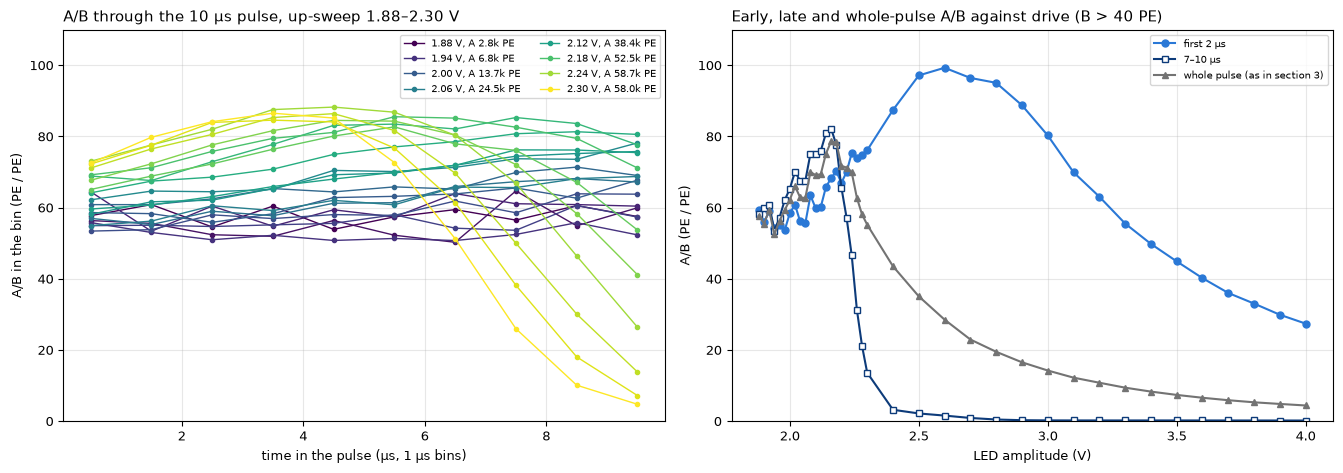

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
ax = axes[0]
sel = [p for p in up_l if 1.88 <= p.amp <= 2.30]
cmap = plt.get_cmap("viridis")
tc = 0.5 * (EDGES_L[1:] + EDGES_L[:-1]) * 1e6
for j, p in enumerate(sel):
    ax.plot(tc[:10], ab_bins[p.amp][:10], "o-", ms=3, lw=1, color=cmap(j / (len(sel) - 1)),
            label=f"{p.amp:.2f} V, A {p.r50['ch'][A]['pe'] / 1e3:.1f}k PE" if j % 3 == 0 or j == len(sel) - 1 else None)
ax.set_xlabel("time in the pulse (µs, 1 µs bins)"); ax.set_ylabel("A/B in the bin (PE / PE)")
ax.set_ylim(0, 110); ax.set_title("A/B through the 10 µs pulse, up-sweep 1.88–2.30 V", loc="left")
ax.legend(ncol=2, fontsize=7)

ax = axes[1]
amps = np.array([p.amp for p in up_l])
first = np.array([ab_bins[a][0] for a in amps])
early = np.array([np.mean(ab_bins[a][0:2]) for a in amps])
late = np.array([np.mean(ab_bins[a][7:10]) for a in amps])
full = np.array([p.r50["ch"][A]["pe"] / p.r50["ch"][B]["pe"] for p in up_l])
ok = np.array([p.r50["ch"][B]["pe"] > 40 for p in up_l])     # B well measured
ax.plot(amps[ok], early[ok], "o-", color=COL[A], ms=5, label="first 2 µs")
ax.plot(amps[ok], late[ok], "s-", color="#0d3b7a", ms=5, mfc="white", label="7–10 µs")
ax.plot(amps[ok], full[ok], "^-", color="0.45", ms=5, label="whole pulse (as in section 3)")
ax.set_xlabel("LED amplitude (V)"); ax.set_ylabel("A/B (PE / PE)"); ax.set_ylim(0, 110)
ax.set_title("Early, late and whole-pulse A/B against drive (B > 40 PE)", loc="left"); ax.legend()
fig.tight_layout(); save(fig, "long_ab_through_pulse"); plt.show()

**What this shows:**
- **1.88–1.98 V (A ≈ 2800–11 000 PE): A/B ≈ 52–60, flat through the pulse.** Both tubes are linear here, and this is the
  10 µs light ratio.
- **From ~2.0 V on (A ≳ 13 000 PE), A/B rises *during* the pulse.** At 2.10 V it goes from 58 in the first µs to 76
  by 9 µs; at 2.16 V from 69 to 85. In the first 1–2 µs A/B stays at 55–62 up to ~2.10 V. So the light split doesn't
  change with drive. **A's gain rises as charge is drawn from its base.** This is the usual supralinearity of a
  resistive divider under load: the last stages lose voltage to their capacitors, and the earlier stages gain it.
- At still higher drive the early ratio rises too: 65–73 at 2.14–2.3 V, ~100 in the first 2 µs at 2.6 V. By then A
  draws 5–20 mA, so ≳ 5–20 nC leave its base within the first microsecond, and it is supralinear almost from the
  start.
- **From ~2.2 V on, A/B collapses late in the pulse:** the base capacitors are depleted and the anode current dies.
  At 2.4 V A/B falls from ~90 to ~2 by 9 µs. The collapse moves earlier with drive, to ~1 µs at 4 V.
- **Why this isn't the LED:**
  - A split change would have to set in after a few µs at a fixed drive, and only above 2.0 V.
  - The LED current is only 1–2 mA at 2.0–2.2 V, so heating in 10 µs at 4 Hz is negligible.
  - With 100 ns pulses A/B stays flat up to 3.3 V, i.e. at twice that LED current (section 3).
  - What this does *not* explain is the 100 ns vs 10 µs difference itself (k 140 vs 57). It is already there in the
    first microsecond and at low light, so it is a property of the LED's light in the two regimes, as in rounds 2–3.

**Light scale for 10 µs, therefore:** the matched scale is fitted on **A = 2500–11 000 PE** (1.88–1.98 V), where
A(t)/B(t) is flat, instead of the default 5000–30 000 PE. The default window spans the supralinear rise. With it,
k_match comes out ~10 % high and the deviation curve gets a spurious bump. Both are shown below.

In [21]:
k_flat = None
ls_l, direct_l, direct_l_err = light_scales(pts_l, (2500.0, 11000.0), 0.0, 0.0)
ls_l_def, _, _ = light_scales(pts_l, (5000.0, 30000.0), 0.0, 0.0)
k_long, k_long_err = ls_l["k"], ls_l["k_err"]
direct_l, direct_l_err = k_long * ls_l["b"], k_long * ls_l["b_err"]      # direct: same k per point, no spline
dv_l = deviations(pts_l, ls_l, direct_l, direct_l_err, b_rel_max=0.03)
dv_l_def = deviations(pts_l, ls_l_def, k_long * ls_l["b"], k_long * ls_l["b_err"], b_rel_max=0.03)
print(f"10 µs matched scale, A in 2500-11000 PE (A(t)/B(t) flat): k = {k_long:.1f} ± {k_long_err:.1f} "
      f"from {ls_l['window'].sum()} points")
print(f"10 µs matched scale, default A in 5000-30000 PE:          k = {ls_l_def['k']:.1f} ± {ls_l_def['k_err']:.1f}")
print(f"regime ratio k(10 µs) / k(100 ns) = {k_long / k_ratio:.3f}")
a_l = dv_l["a"]
imax = int(np.nanargmax(a_l))
print(f"A's delivered charge peaks at {a_l[imax]:,.0f} PE = {a_l[imax] * Q1[A] / 1e3:.1f} nC "
      f"({pts_l[imax].sweep} {pts_l[imax].amp:.2f} V, true light {ls_l['light'][imax]:,.0f} PE)")
dev = dv_l["lin"]["dev"]
bump = np.nanargmax(np.where(ls_l["use_b"], dev, np.nan))
print(f"largest excess: {100 * dev[bump]:+.0f} % at {ls_l['light'][bump]:,.0f} PE true light ({pts_l[bump].amp:.2f} V)")
for lv in (0.05, 0.10):
    print(f"A charge {lv:.0%} low (for good) at true light: {dv_l['lin']['cross'][lv]:,.0f} PE "
          f"(default window: {dv_l_def['lin']['cross'][lv]:,.0f} PE)")


def onset_above(light, dev, level):
    # lowest light where the excess passes +level and the next point stays above it (interpolated)
    o = np.argsort(light)
    x, d = light[o], dev[o]
    for i in range(1, len(d) - 1):
        if d[i - 1] <= level < d[i] and d[i + 1] > level:
            return float(x[i - 1] + (level - d[i - 1]) / (d[i] - d[i - 1]) * (x[i] - x[i - 1]))
    return None


u = (sweeps(pts_l) == "up") & np.isfinite(dev)   # incl. the points below the hand-over (deviation 0 by definition)
excess_on = {lv: onset_above(ls_l["light"][u], dev[u], lv) for lv in (0.05, 0.10)}
for lv, x in excess_on.items():
    print(f"A charge {lv:.0%} HIGH (supralinear) from true light {x:,.0f} PE")
i4 = int(np.argmax(ls_l["light"]))
print(f"top of the scan ({pts_l[i4].amp:.1f} V): true light {ls_l['light'][i4]:,.0f} PE, A {a_l[i4]:,.0f} PE")

10 µs matched scale, A in 2500-11000 PE (A(t)/B(t) flat): k = 57.4 ± 0.5 from 8 points
10 µs matched scale, default A in 5000-30000 PE:          k = 63.2 ± 1.4
regime ratio k(10 µs) / k(100 ns) = 0.417
A's delivered charge peaks at 58,744 PE = 53.1 nC (up 2.24 V, true light 48,225 PE)
largest excess: +37 % at 35,394 PE true light (2.16 V)
A charge 5% low (for good) at true light: 61,053 PE (default window: 61,628 PE)
A charge 10% low (for good) at true light: 64,412 PE (default window: 64,706 PE)
A charge 5% HIGH (supralinear) from true light 11,985 PE
A charge 10% HIGH (supralinear) from true light 21,308 PE
top of the scan (4.0 V): true light 379,582 PE, A 29,249 PE


### Measured vs true light (10 µs)
The true light is k × B with the 10 µs k from the flat region. The orange band marks where B's own pulse shape
starts to change (see the self-check below). There the true light may be up to ~5 % low.

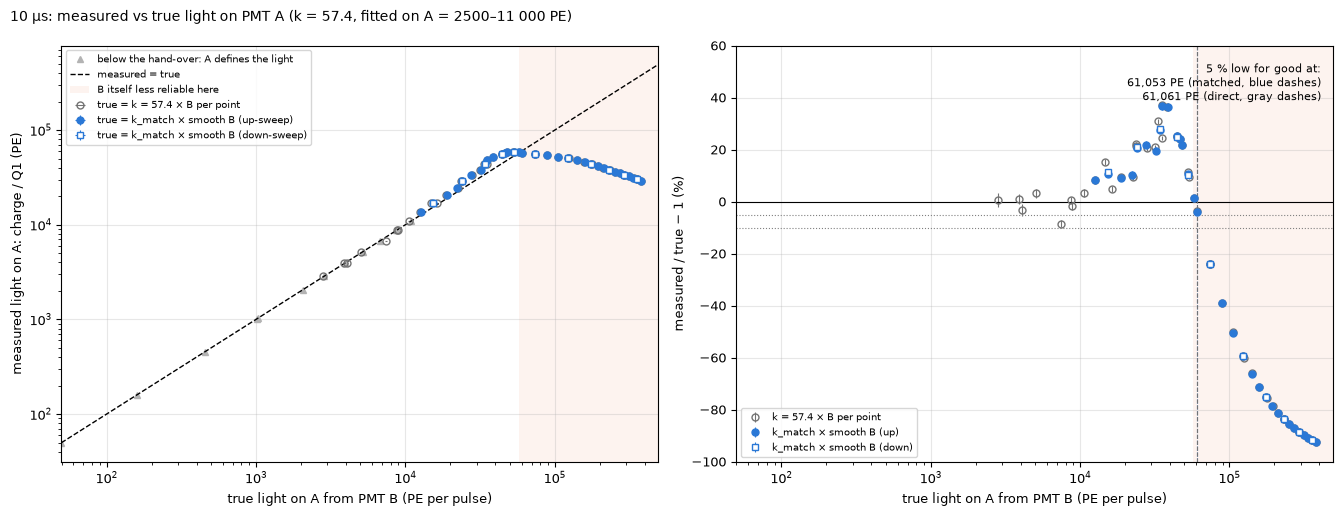

In [22]:
B_CAUTION_PE = 1000.0                          # B above ~1 nC: its late/early falls by ~10 % (self-check below)
fig = plot_measured_vs_true(pts_l, ls_l, direct_l, direct_l_err, dv_l, f"k = {k_long:.1f}",
                            f"10 µs: measured vs true light on PMT A (k = {k_long:.1f}, fitted on A = 2500–11 000 PE)",
                            b_caution=k_long * B_CAUTION_PE, top_dev=60)
save(fig, "long_measured_vs_true"); plt.show()

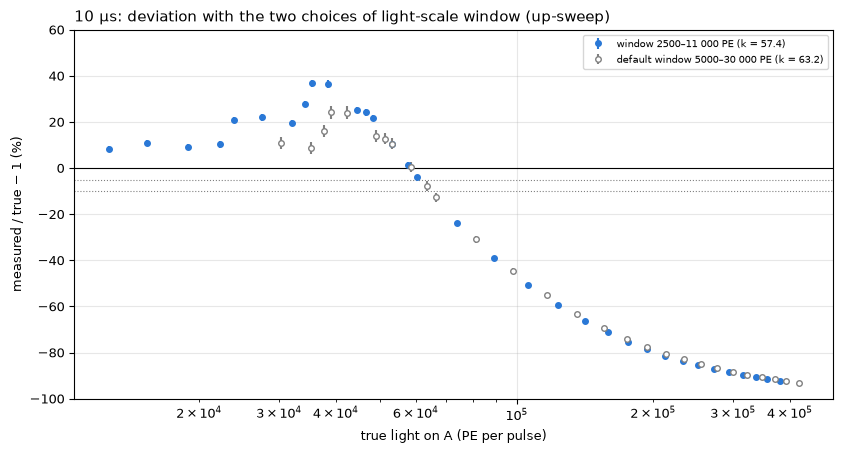

In [23]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for lsx, dvx, lab, col in ((ls_l, dv_l, f"window 2500–11 000 PE (k = {ls_l['k']:.1f})", COL[A]),
                           (ls_l_def, dv_l_def, f"default window 5000–30 000 PE (k = {ls_l_def['k']:.1f})", "0.5")):
    u = lsx["use_b"] & (sweeps(pts_l) == "up")
    ax.errorbar(lsx["light"][u], 100 * dvx["lin"]["dev"][u], 100 * dvx["lin"]["dev_err"][u], fmt="o", ms=4,
                color=col, mfc=col if col != "0.5" else "white", label=lab)
for lv in (-5, -10):
    ax.axhline(lv, color="0.5", ls=":", lw=0.8)
ax.axhline(0, color="k", lw=0.8)
ax.set_xscale("log"); ax.set_ylim(-100, 60)
ax.set_xlabel("true light on A (PE per pulse)"); ax.set_ylabel("measured / true − 1 (%)")
ax.set_title("10 µs: deviation with the two choices of light-scale window (up-sweep)", loc="left"); ax.legend()
fig.tight_layout(); save(fig, "long_light_scale_choice"); plt.show()

**Results (10 µs):**
- **The 10 µs light ratio is k = 57.4 ± 0.5,** 0.42 × the 100 ns value.
- **A is supralinear before it depletes.**
  - Its charge is **5 % high from ≈ 12 000 PE** of true light and **10 % high from ≈ 21 000 PE**.
  - The excess peaks at **+37 % at ≈ 35 000 PE** (2.16 V).
  - Then the base runs out of charge.
- **A's delivered charge tops out at ≈ 58 700 PE ≈ 53 nC** at 2.24 V (true light ≈ 48 000 PE).
  - Rounds 2 and 3 both gave ~38 nC.
  - It then *falls* while the light keeps rising: 29 000 PE at 4 V, where the true light is ≈ 380 000 PE.
  - At 4 V the anode current stops ~1 µs into the pulse.
- **The "5 % low" point lies on the far side of the bump,** at ≈ 61 000 PE of true light (10 % low at ≈ 64 000 PE),
  where the collapsing response crosses the line. It isn't a linear-range limit in the usual sense. **For 10 µs pulses A
  is within ±5 % of linear only up to ~12 000 PE (~11 nC), and within ±10 % up to ~21 000 PE.**
- **The default window (5000–30 000 PE)** puts k 10 % higher (63.2). The supralinear excess then looks like a
  smaller bump (+10–24 %), as in the chain's automatic analysis. The collapse point (~61 600 PE) hardly moves. The
  flat-A(t)/B(t) window is the better-founded choice.
- Up- and down-sweeps agree.

### Raw waveforms of PMT A through depletion
As for 100 ns: single pulses (thin), the mean (thick), and the linear expectation from B (dashed; B smoothed over
0.2 µs). At 1.94 V A follows B. By 2.10 V A is above the expectation late in the pulse (supralinear). From ~2.2 V on, the
current collapses before the light ends, earlier at each step.

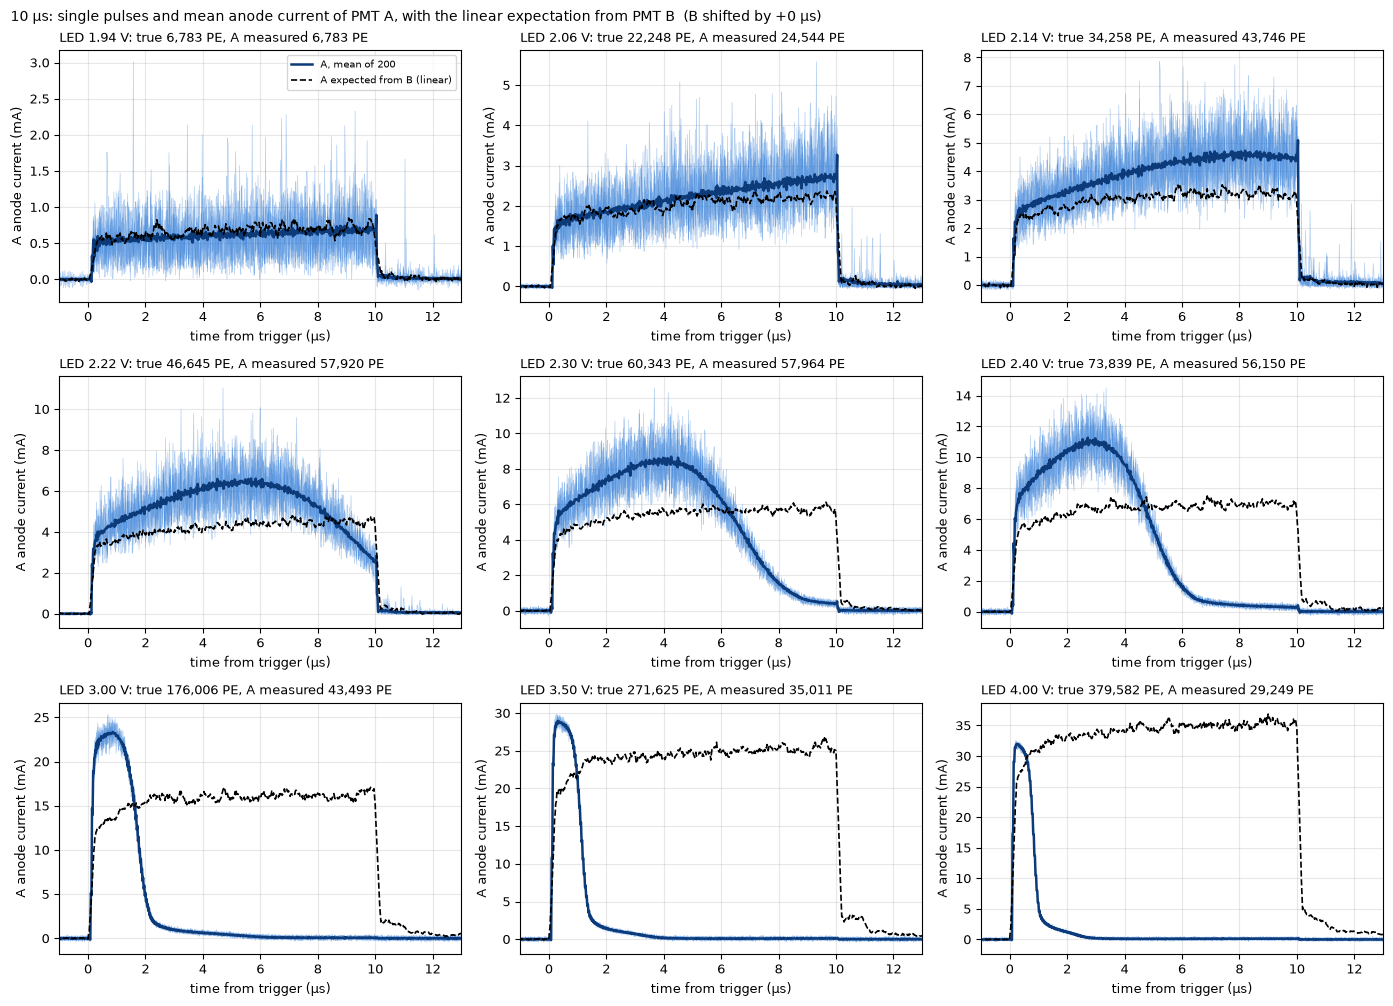

In [24]:
fig = plot_raw("long", pts_l, ls_l, [1.94, 2.06, 2.14, 2.22, 2.30, 2.40, 3.00, 3.50, 4.00], k_long, 1.96, 10,
               (-1, 13), 1e-6, 4, "10 µs: single pulses and mean anode current of PMT A, with the linear expectation from PMT B")
save(fig, "long_raw_waveforms"); plt.show()

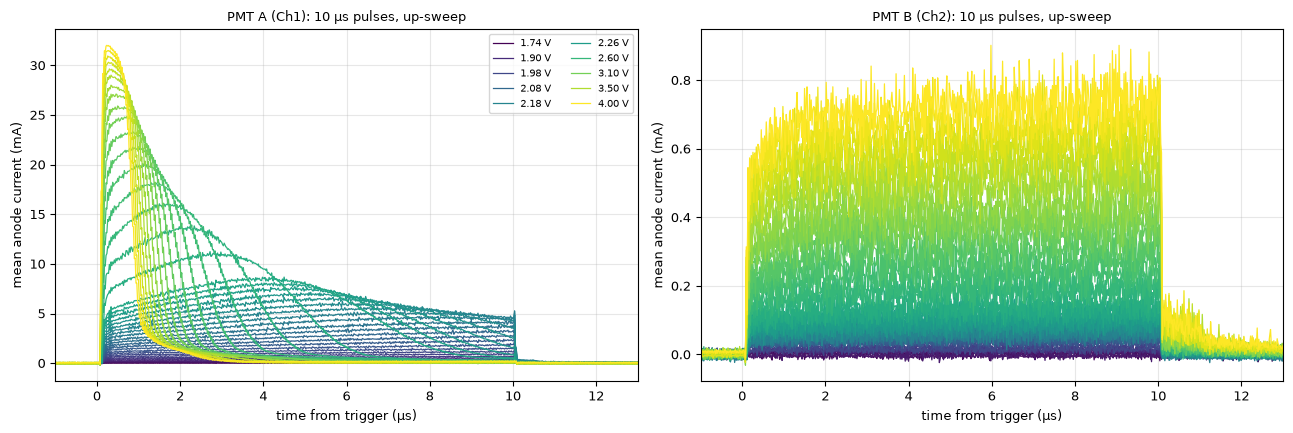

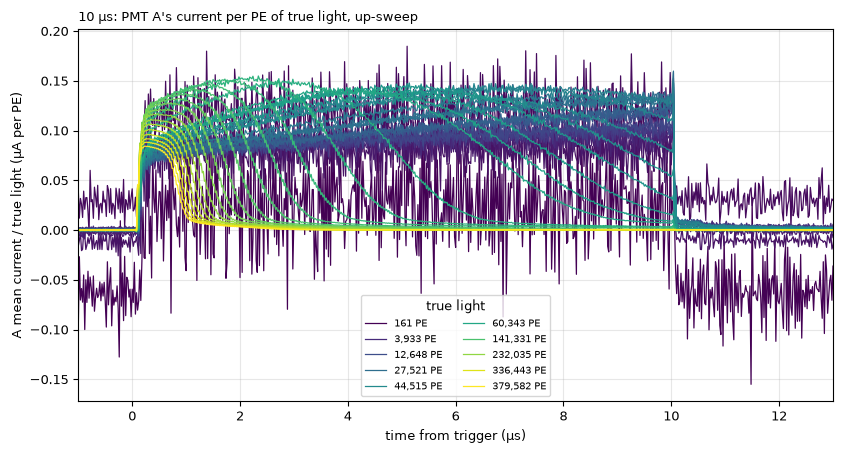

In [25]:
fig = sat_plots.plot_waveforms(pts_l, "10 µs", xlim_us=(-1.0, 13.0))
save(fig, "long_mean_waveforms"); plt.show()
fig = plot_response_per_pe("long", pts_l, ls_l, (-1, 13), 1e-6, "10 µs: PMT A's current per PE of true light, up-sweep")
save(fig, "long_response_per_pe"); plt.show()

### Self-check of the reference: B's pulse shape
B is the light reference only while B itself is linear. Its late/early charge ratio (7–9 µs over 1–3 µs) should
follow the LED's own light shape and not drop as B's charge grows. A's ratio is shown for comparison.

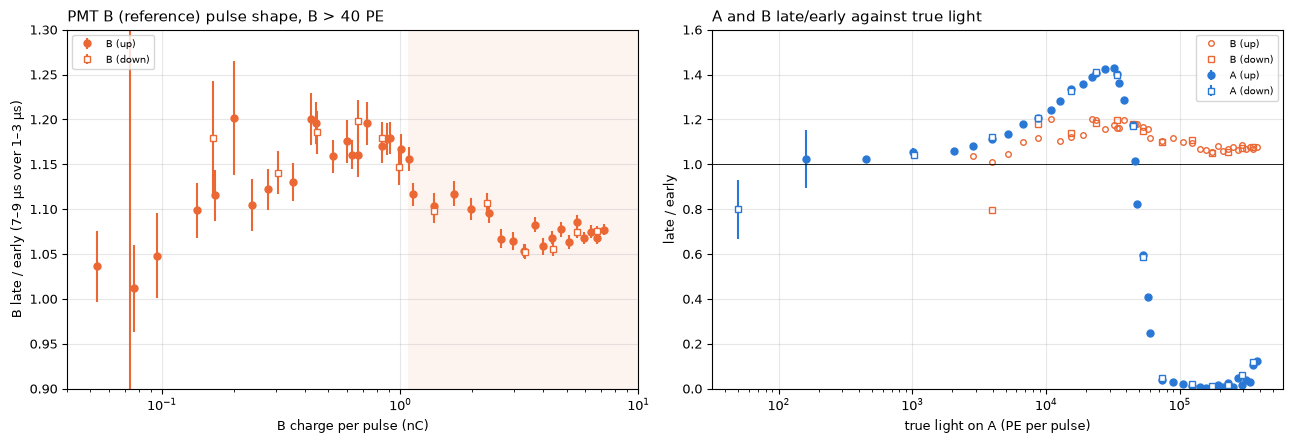

In [26]:
le_a, le_a_err = arrays(pts_l, A, "late_early")
le_b, le_b_err = arrays(pts_l, B, "late_early")
bq_nc = ls_l["b"] * Q1[B] / 1e3
sw = sweeps(pts_l)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
for s, m in (("up", "o"), ("down", "s")):
    sel = (sw == s) & (ls_l["b"] > 40)
    ax.errorbar(bq_nc[sel], le_b[sel], le_b_err[sel], fmt=m, ms=5, color=COL[B], mfc=COL[B] if s == "up" else "white",
                label=f"B ({s})")
ax.axvspan(B_CAUTION_PE * Q1[B] / 1e3, 10, color=COL[B], alpha=0.08, lw=0)
ax.set_xscale("log"); ax.set_xlim(0.04, 10); ax.set_ylim(0.9, 1.3)
ax.set_xlabel("B charge per pulse (nC)"); ax.set_ylabel("B late / early (7–9 µs over 1–3 µs)")
ax.set_title("PMT B (reference) pulse shape, B > 40 PE", loc="left"); ax.legend()
ax = axes[1]
for s, m in (("up", "o"), ("down", "s")):
    sel = sw == s
    ax.errorbar(ls_l["light"][sel], le_a[sel], le_a_err[sel], fmt=m, ms=5, color=COL[A],
                mfc=COL[A] if s == "up" else "white", label=f"A ({s})")
    selb = sel & (ls_l["b"] > 40)
    ax.plot(ls_l["light"][selb], le_b[selb], m, ms=4, color=COL[B], mfc="none", label=f"B ({s})")
ax.axhline(1, color="k", lw=0.6)
ax.set_xscale("log"); ax.set_ylim(0, 1.6)
ax.set_xlabel("true light on A (PE per pulse)"); ax.set_ylabel("late / early")
ax.set_title("A and B late/early against true light", loc="left"); ax.legend()
fig.tight_layout(); save(fig, "long_shape_checks"); plt.show()

- **B's late/early** rises from ~1.0 at the dim end to ~1.15–1.2 at 0.2–1 nC, the same as A's in its linear range. That
  is the LED's light getting more "late-heavy" with drive.
- **Above ~1 nC, B's late/early falls to ~1.06** by ~2.5 nC, then stays flat up to 7 nC (4 V).
  - Progressive depletion of B would keep falling as B's charge triples, so this more likely is the LED's light
    shape changing. Round 3 saw B's late/early move from ~3 nC.
  - It could still be a ≲ 10 % late-pulse loss in B. Then the true light above ~1 nC on B (≳ 57 000 PE, the orange
    band) would be up to ~5 % low.
  - That doesn't change the conclusions: A is already collapsing there (10–90 % low).
- **A's late/early** climbs to 1.43 (supralinear late in the pulse), then drops to ~0 as the anode current dies before
  the light ends.

**Would 10⁶ PE on A be possible?** B reaches 7 nC at 4 V, past its own depletion onset. To put ~10⁶ PE of 10 µs light
on A with B still linear, B would need to be attenuated ~10× further, and the drive would have to go to ~7–8 V.

## 6. Summary

In [27]:
c_s, c_l = dv_s["lin"]["cross"], dv_l["lin"]["cross"]
summary["short_100ns"] = {"k_match": ls_s["k"], "k_match_err": ls_s["k_err"], "k_ratio_scan_B_charge": k_ratio_q,
                          "charge_5pct_low_PE": c_s[0.05], "charge_10pct_low_PE": c_s[0.10],
                          "charge_5pct_low_PE_direct_k": dv_s["cross_d"][0.05],
                          "charge_10pct_low_PE_direct_k": dv_s["cross_d"][0.10],
                          "peak_mA_at_top": float(pk.max()), "true_light_at_top_PE": float(ls_s["light"].max()),
                          "excluded": "up 2.000 V (recorded at the 0.5 V start level)"}
summary["long_10us"] = {"k": k_long, "k_err": k_long_err, "k_window_A_PE": [2500, 11000],
                        "k_default_window": ls_l_def["k"], "max_charge_PE": float(a_l[imax]),
                        "max_charge_nC": float(a_l[imax] * Q1[A] / 1e3), "max_excess_pct": float(100 * dev[bump]),
                        "max_excess_true_light_PE": float(ls_l["light"][bump]),
                        "charge_5pct_high_from_PE": excess_on[0.05], "charge_10pct_high_from_PE": excess_on[0.10],
                        "charge_5pct_low_PE": c_l[0.05], "charge_10pct_low_PE": c_l[0.10],
                        "excluded": "up 1.700 V (recorded at the 0.5 V start level)"}
(OUT / "summary.json").write_text(json.dumps(summary, indent=1, default=lambda x: None if x is None else float(x)))
print(json.dumps(summary, indent=1, default=lambda x: None if x is None else float(x)))
print("figures and summary.json in", OUT)

{
 "spe": {
  "PMT A": {
   "led_V": 1.81,
   "q1_pC": 0.9035643174790468,
   "q1_err_pC": 0.012778586787609767,
   "sigma1_pC": 0.2497431418342879,
   "gain": 5639604.886904416,
   "mu_fit": 0.1826226467396179,
   "mu_zero_pe": 0.17207829265324442
  },
  "PMT B": {
   "led_V": 2.055,
   "q1_pC": 1.0803940413822282,
   "q1_err_pC": 0.014361847309168967,
   "sigma1_pC": 0.27805411239917693,
   "gain": 6743289.213280514,
   "mu_fit": 0.13356509410420062,
   "mu_zero_pe": 0.1490856906585816
  }
 },
 "k": {
  "ratio_scan": 137.52246198531557,
  "ratio_scan_err": 2.4369049431913328,
  "ratio_scan_chi2_dof": 0.8179800787682822,
  "ratio_scan_B_charge": 140.43634670544523,
  "ratio_scan_B_charge_err": 2.0886659870868742,
  "split_run": 131.85994718306486,
  "split_run_err": 6.275239162076324
 },
 "short_100ns": {
  "k_match": 142.46871642452646,
  "k_match_err": 0.7604111076172454,
  "k_ratio_scan_B_charge": 140.43634670544523,
  "charge_5pct_low_PE": 1512.0114574649813,
  "charge_10pct_low_P

| | Round 4 (this run) | Round 3 (2026-10-27) | Round 2 (2026-10-08) |
|---|---|---|---|
| pulser | Siglent SDG2082X | AD3 | AD3 |
| SPE Q1, A / B (pC) | 0.904 / 1.080 | 0.935 / 1.089 | |
| light ratio A:B, short (low light) | **137.5 ± 2.4** (100 ns; B counted) | 27.8 ± 0.5 (250 ns) | 2395 (100 ns) |
| light ratio A:B, 10 µs | **57.4 ± 0.5** (where A(t)/B(t) is flat) | ≈ 10–14 | 1105 |
| 100 ns charge: 5 % / 10 % low at | **≈ 1500–1730 / 2100–2250 PE** | (250 ns: 2960 / 4480) | 1330 / 1590 PE |
| 100 ns peak-current plateau | **~34 mA** | ~38 mA (250 ns) | ~39 mA |
| 10 µs: within ±5 % / ±10 % of linear up to | **~12 000 / ~21 000 PE** (supralinear, up to +37 %) | 5 % low at ~42 800 (uncertain) | 5 % low at ~33 400 |
| 10 µs: max delivered charge | **≈ 58 700 PE ≈ 53 nC** | ~38 nC | ~38 nC |

The range quoted for 100 ns spans the two light scales: matched, and direct with the ratio-scan k_q.

**Conclusions:**
1. **SPE and light ratio:**
   - The calibration is clean and close to round 3.
   - The 100 ns light ratio is well determined (±1.7 %), flat over 2.0–2.4 V, and reproduced by an independent run.
   - It agrees with the A/B of the saturation scan's linear part (k_match, 0.9σ).
   - The split stayed fixed for the whole afternoon: the rigid mounting works.
2. **100 ns (space charge):**
   - A is linear to ~1 % up to ~1000 PE.
   - Its peak current saturates at ~34 mA.
   - The anode charge is 5 % low at ~1500–1700 PE, 10 % low at ~2100–2250 PE, and 41 % low at 6200 PE.
   - This is consistent with round 2's 100 ns numbers, now with properly shaped 100 ns pulses.
3. **10 µs (depletion):**
   - A first becomes **supralinear**: its gain rises *during* the pulse as charge is drawn from the base, reaching
     +37 % at ~35 000 PE.
   - It then **collapses**: the delivered charge tops out at ~53 nC and the anode current stops ever earlier in the
     pulse.
   - The A(t)/B(t) analysis shows this is a gain change in A, not a change of the light split with drive. That settles
     the "drive-dependent A/B" question left open in round 3.
   - For 10 µs light, A is within ±5 % of linear only up to ~12 000 PE.
4. **Data quality:**
   - One acquisition bug cost the first point of each scan; it is fixed.
   - The reference B is fine everywhere except possibly at the top of the 10 µs scan (B > ~1 nC, ≤ 5 % effect),
     where A has already collapsed.

**Next:**
- Use the A(t)/B(t)-flat window for the long-pulse light scale from now on (`MATCH_A_WINDOW["long"]` in
  `saturation_r2.ipynb`).
- Attenuate B ~10× and raise the drive limit for a high-light 10 µs run toward 10⁶ PE on A.
- To study the supralinear phase itself, finer LED steps at 1.95–2.25 V (10 µs) would help, ideally with dynode 8
  reconnected to see whether the late stages lose gain while the early ones gain.